<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_2%EC%A1%B0_Project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **제주 특산물 가격 예측 AI 경진대회**

https://dacon.io/competitions/official/236176/overview/description

# 1. 환경 설정

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q koreanize-matplotlib lightgbm statsmodels
import logging, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
try:
    import koreanize_matplotlib
except ImportError:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

TRAIN_PATH = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/train.csv'
TEST_PATH  = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/test.csv'
TRADE_PATH = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/international_trade.csv'
SUB_PATH   = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/sample_submission.csv'

ITEMS = ['TG', 'CR', 'CB', 'RD', 'BC']
ITEM_KR = {'TG': '감귤', 'CR': '당근', 'CB': '양배추', 'RD': '무', 'BC': '브로콜리'}
H = 28

# 2. 데이터 불러오기 → 날짜 × 시계열 행렬로 변환

가격 행렬: (1551, 39) | 결측(=test 구간) 행 수: 28
거래일 비율: 40.3%


series,BC_A_J,BC_A_S,BC_B_J,BC_B_S,BC_C_J,BC_C_S,BC_D_J,BC_E_J
2023-03-29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-03-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


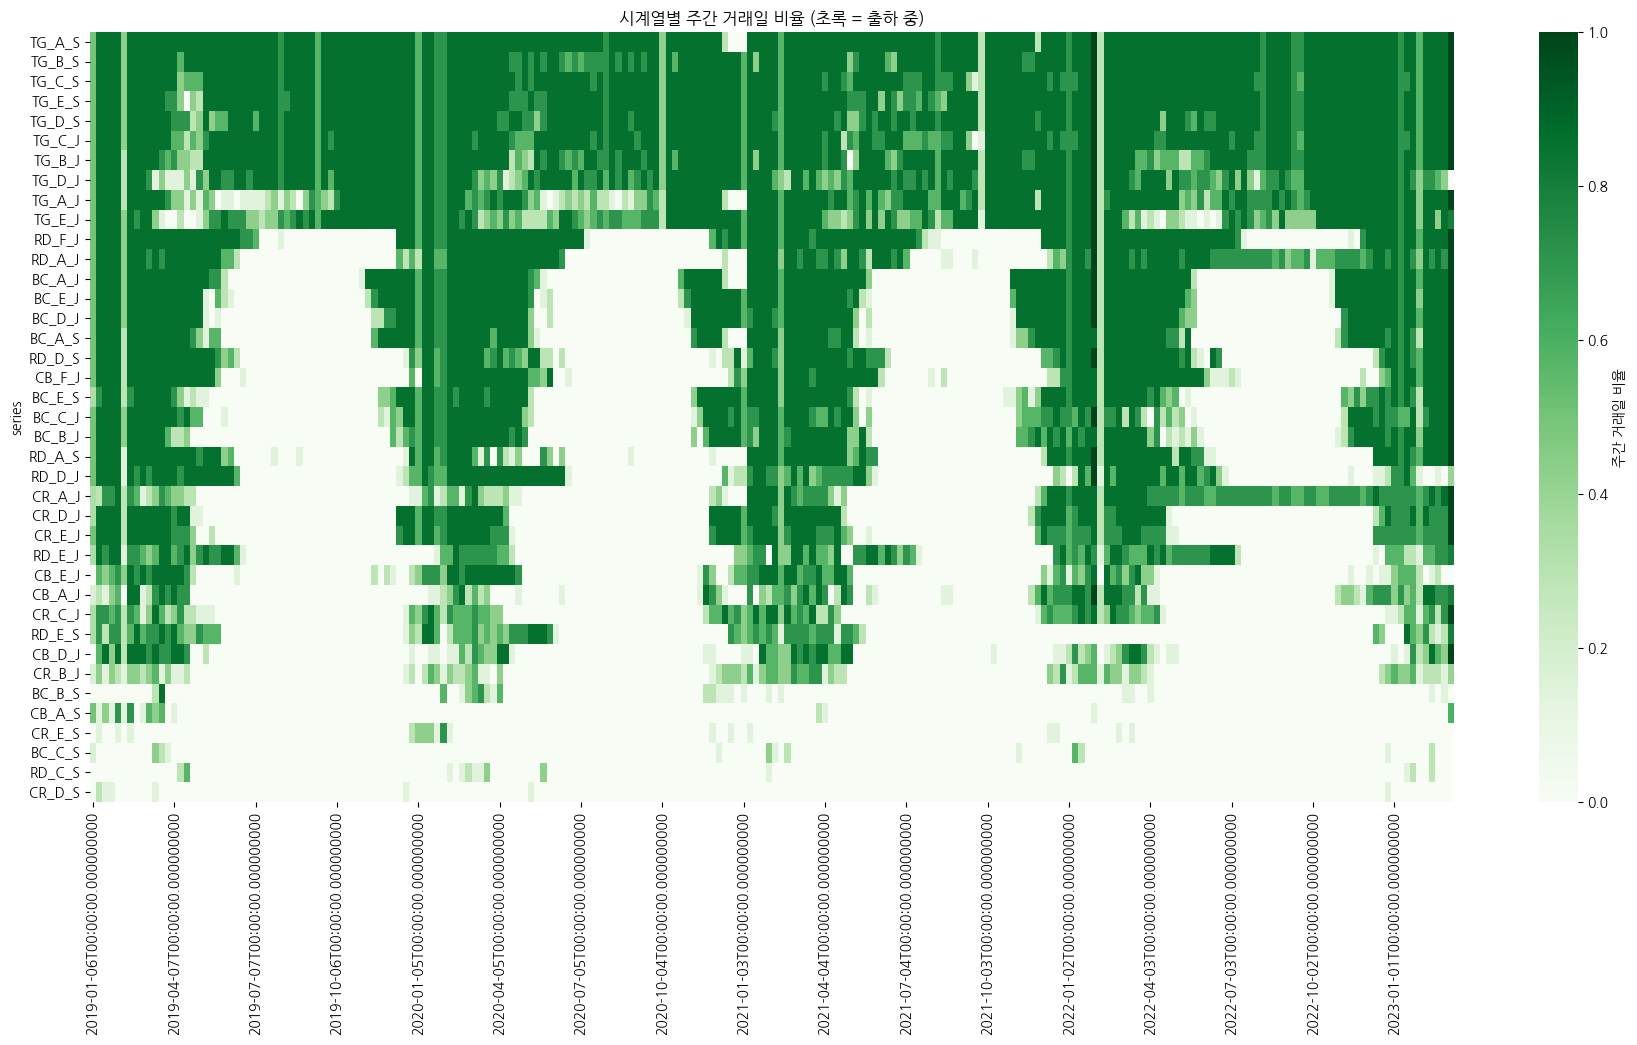

,2019년,2020년,2021년,2022년,2023년,평균
series,,,,,,
CR_D_S,0,0,0,0,0,0.000
BC_C_S,0,0,0,1,0,0.200
CR_E_S,0,1,0,0,0,0.200
RD_C_S,1,0,0,0,0,0.200
CB_A_S,4,0,0,0,1,1.000
BC_B_S,1,4,0,0,0,1.200
CR_B_J,1,2,9,4,2,4.000
CB_D_J,13,5,13,6,4,9.200
CB_A_J,9,5,16,15,7,11.200


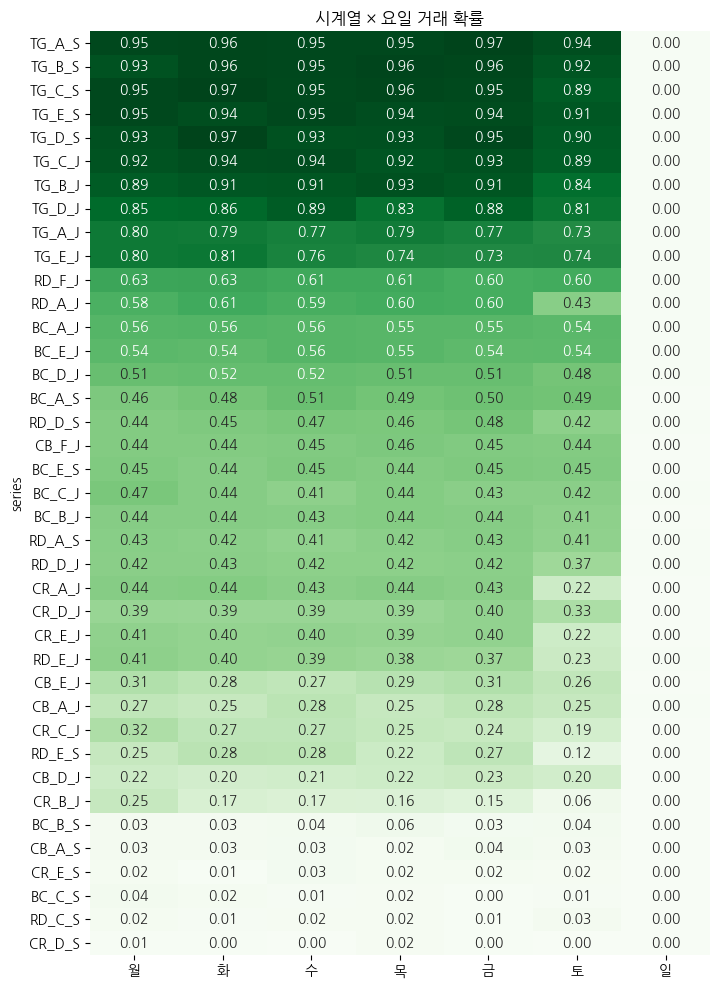

In [ ]:
train = pd.read_csv(TRAIN_PATH).rename(columns={'supply(kg)': 'supply', 'price(원/kg)': 'price'})
test = pd.read_csv(TEST_PATH)
trade = pd.read_csv(TRADE_PATH)
sub = pd.read_csv(SUB_PATH)
for d in (train, test):
    d['timestamp'] = pd.to_datetime(d['timestamp'])
    d['series'] = d['item'] + '_' + d['corporation'] + '_' + d['location']

dates = pd.date_range(train.timestamp.min(), test.timestamp.max())
SERIES = sorted(train.series.unique())
P = train.pivot(index='timestamp', columns='series', values='price').reindex(dates)[SERIES]   # 가격 (test 구간 NaN)
S = train.pivot(index='timestamp', columns='series', values='supply').reindex(dates)[SERIES]  # 공급량
T = (P > 0).astype(float).where(P.notna())                                                     # 거래 여부
item_of = pd.Series({s: s[:2] for s in SERIES})

print('가격 행렬:', P.shape, '| 결측(=test 구간) 행 수:', P.isna().all(axis=1).sum())
print('거래일 비율: {:.1%}'.format(T.stack().mean()))
display(P.tail(3).iloc[:, :8])

wk_rate = T.loc[:'2023-03-03'].resample('W').mean()
order = wk_rate.mean().sort_values(ascending=False).index
plt.figure(figsize=(22, 10))
sns.heatmap(wk_rate[order].T, cmap='Greens', cbar_kws={'label': '주간 거래일 비율'}, xticklabels=13)
plt.title('시계열별 주간 거래일 비율 (초록 = 출하 중)'); plt.show()


#시즌 길이: 연도별로 거래일 비율이 50%를 넘는 주(week)의 수
season = (wk_rate > 0.5).groupby(wk_rate.index.year).sum().T
season.columns = [f'{c}년' for c in season.columns]
season['평균'] = season.iloc[:, :4].mean(axis=1)
display(season.sort_values('평균').round(1))


#일요일을 뺀 요일별 거래 확률 — 시계열마다 쉬는 요일 패턴이 다른가
dow_rate = T.loc[:'2023-03-03'].groupby(T.loc[:'2023-03-03'].index.dayofweek).mean().T
dow_rate.columns = ['월', '화', '수', '목', '금', '토', '일']
plt.figure(figsize=(8, 12))
sns.heatmap(dow_rate.loc[order], annot=True, fmt='.2f', cmap='Greens', cbar=False)
plt.title('시계열 × 요일 거래 확률'); plt.show()

# 3. EDA 분석

### EDA 1 - 거래 시즌 패턴으로 시계열 군집화

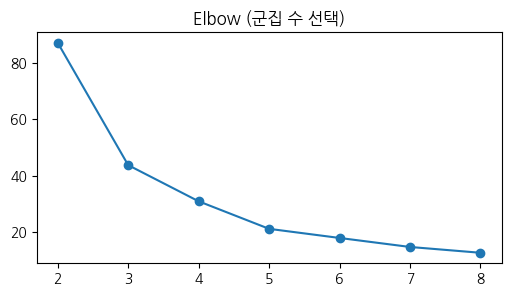

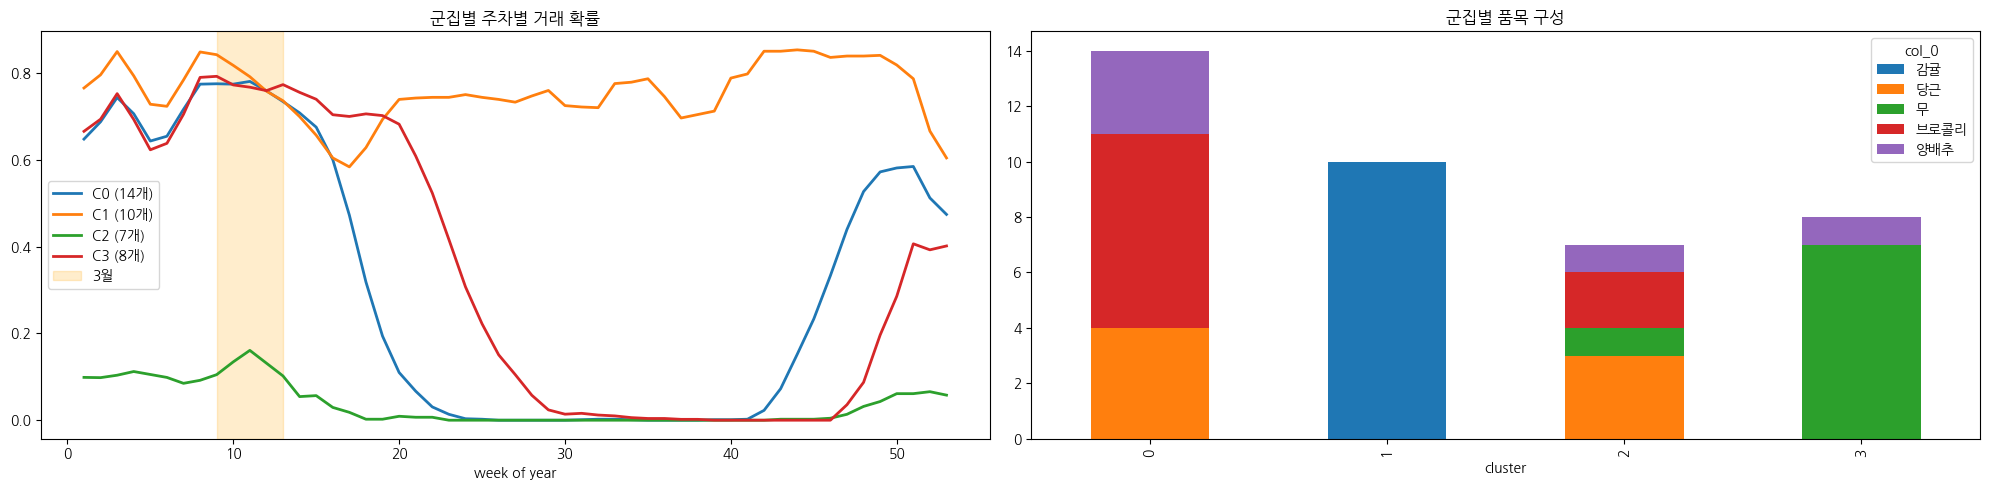

cluster
0    [BC_A_J, BC_A_S, BC_B_J, BC_C_J, BC_D_J, BC_E_...
1    [TG_A_J, TG_A_S, TG_B_J, TG_B_S, TG_C_J, TG_C_...
2    [BC_B_S, BC_C_S, CB_A_S, CR_B_J, CR_D_S, CR_E_...
3    [CB_F_J, RD_A_J, RD_A_S, RD_D_J, RD_D_S, RD_E_...


In [ ]:
from sklearn.cluster import KMeans

hist = T.loc[:'2022-02-28']
prof = hist.groupby(hist.index.isocalendar().week.values).mean().T   # 39 × 53
prof = prof.T.rolling(3, min_periods=1, center=True).mean().T   # 주차 방향으로 살짝 평활
inertia = [KMeans(k, n_init=20, random_state=0).fit(prof).inertia_ for k in range(2, 9)]
plt.figure(figsize=(6, 3)); plt.plot(range(2, 9), inertia, 'o-'); plt.title('Elbow (군집 수 선택)'); plt.show()

K = 4
km = KMeans(K, n_init=20, random_state=0).fit(prof)
cluster = pd.Series(km.labels_, index=SERIES, name='cluster')

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
for k in range(K):
    ax[0].plot(prof.columns, prof[cluster == k].mean(), lw=2, label=f'C{k} ({(cluster == k).sum()}개)')
ax[0].axvspan(9, 13, color='orange', alpha=.2, label='3월'); ax[0].legend(); ax[0].set_title('군집별 주차별 거래 확률')
ax[0].set_xlabel('week of year')
pd.crosstab(cluster, item_of.map(ITEM_KR)).plot.bar(stacked=True, ax=ax[1], title='군집별 품목 구성')
plt.tight_layout(); plt.show()
print(cluster.groupby(cluster).apply(lambda x: list(x.index)).to_string())

### EDA 2 - 이상치 Hampel 필터

이상치 개수(시계열 상위 10):


,n
series,
TG_A_J,74
TG_B_J,69
TG_C_J,68
TG_D_S,67
TG_D_J,61
TG_E_J,59
TG_E_S,55
TG_B_S,54
CR_A_J,48


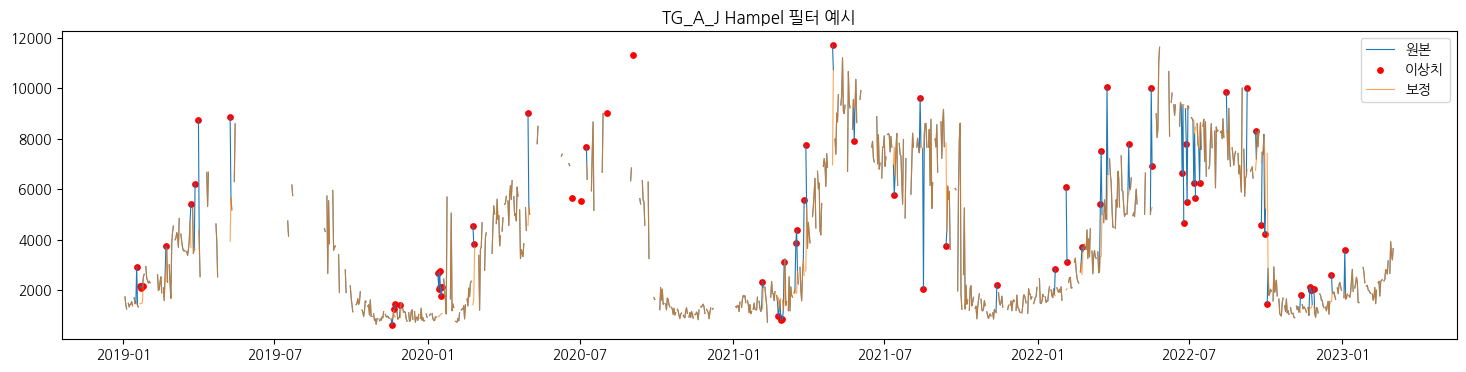

In [ ]:
Pnz = P.where(P > 0)
med = Pnz.rolling(15, min_periods=3).median()
mad = (Pnz - med).abs().rolling(15, min_periods=3).median()
is_out = (Pnz - med).abs() > 3 * 1.4826 * mad.replace(0, np.nan)
Pclean = Pnz.mask(is_out, med)

print('이상치 개수(시계열 상위 10):'); display(is_out.sum().sort_values(ascending=False).head(10).to_frame('n'))
s_ex = is_out.sum().idxmax()
fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(Pnz[s_ex], lw=.8, label='원본'); ax.scatter(Pnz.index[is_out[s_ex]], Pnz[s_ex][is_out[s_ex]], c='r', s=15, label='이상치')
ax.plot(Pclean[s_ex], lw=.8, alpha=.7, label='보정'); ax.set_title(f'{s_ex} Hampel 필터 예시'); ax.legend(); plt.show()

### EDA 3 - 가격을 시계열 수준으로 나눠 보기 (정규화)

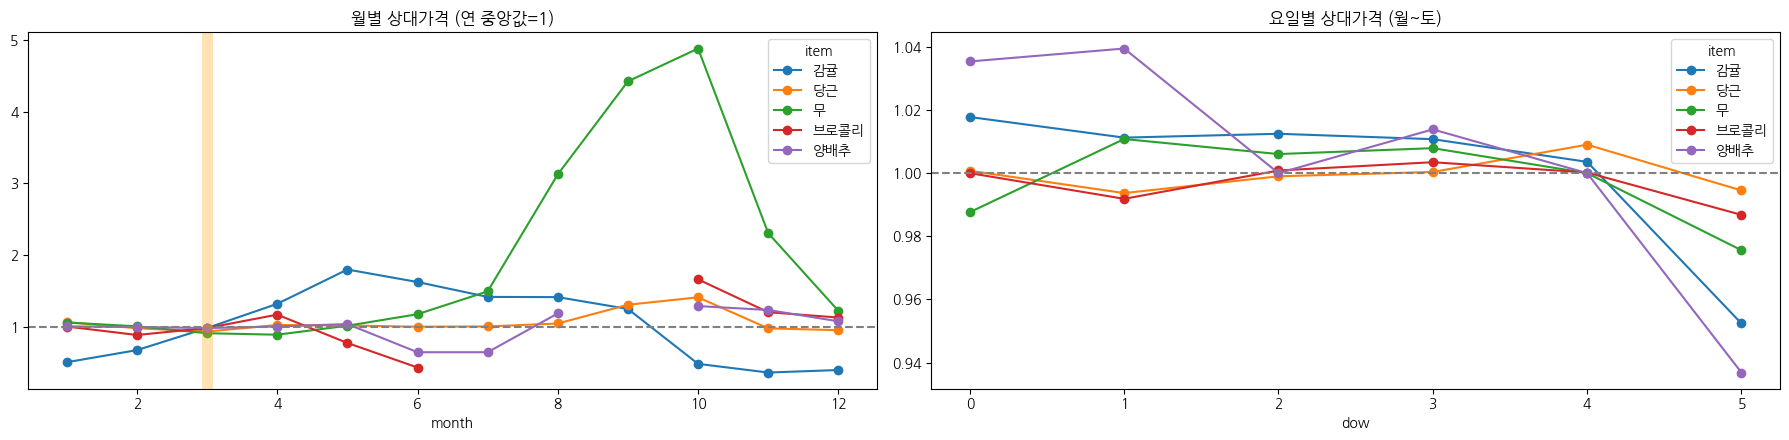

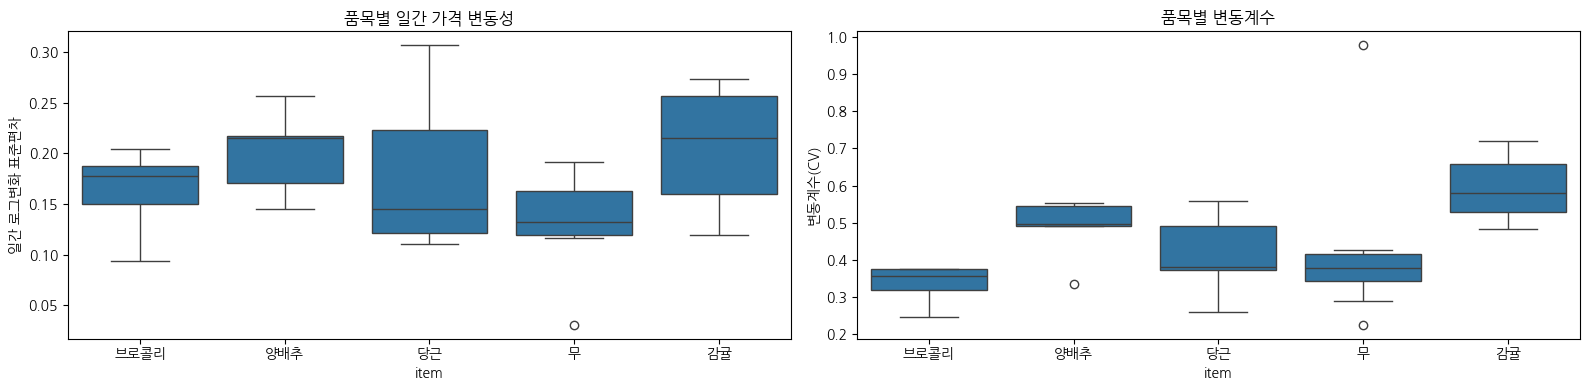

In [ ]:
yr_med = Pclean.groupby(Pclean.index.year).transform('median')
R = Pclean / yr_med   # 상대가격
rel = R.loc[:'2023-03-03'].stack().rename('rel').reset_index()
rel.columns = ['timestamp', 'series', 'rel']
rel['item'] = rel.series.str[:2].map(ITEM_KR)
rel['month'] = rel.timestamp.dt.month
rel['dow'] = rel.timestamp.dt.dayofweek

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
rel.groupby(['month', 'item']).rel.median().unstack().plot(ax=ax[0], marker='o', title='월별 상대가격 (연 중앙값=1)')
ax[0].axhline(1, c='gray', ls='--'); ax[0].axvline(3, c='orange', lw=8, alpha=.3)
rel[rel.dow < 6].groupby(['dow', 'item']).rel.median().unstack().plot(ax=ax[1], marker='o', title='요일별 상대가격 (월~토)')
ax[1].axhline(1, c='gray', ls='--')
plt.tight_layout(); plt.show()

# %%
# 시계열별 변동성: 일간 변화율 분포 & 변동계수
chg = np.log(Pclean).diff()
vol = pd.DataFrame({'일간 로그변화 표준편차': chg.std(), '변동계수(CV)': Pnz.std() / Pnz.mean(), 'item': item_of.map(ITEM_KR)})
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(data=vol, x='item', y='일간 로그변화 표준편차', ax=ax[0]); ax[0].set_title('품목별 일간 가격 변동성')
sns.boxplot(data=vol, x='item', y='변동계수(CV)', ax=ax[1]); ax[1].set_title('품목별 변동계수')
plt.tight_layout(); plt.show()

### EDA 4 - 시계열 분해 (STL) 추세와 계절성의 비중

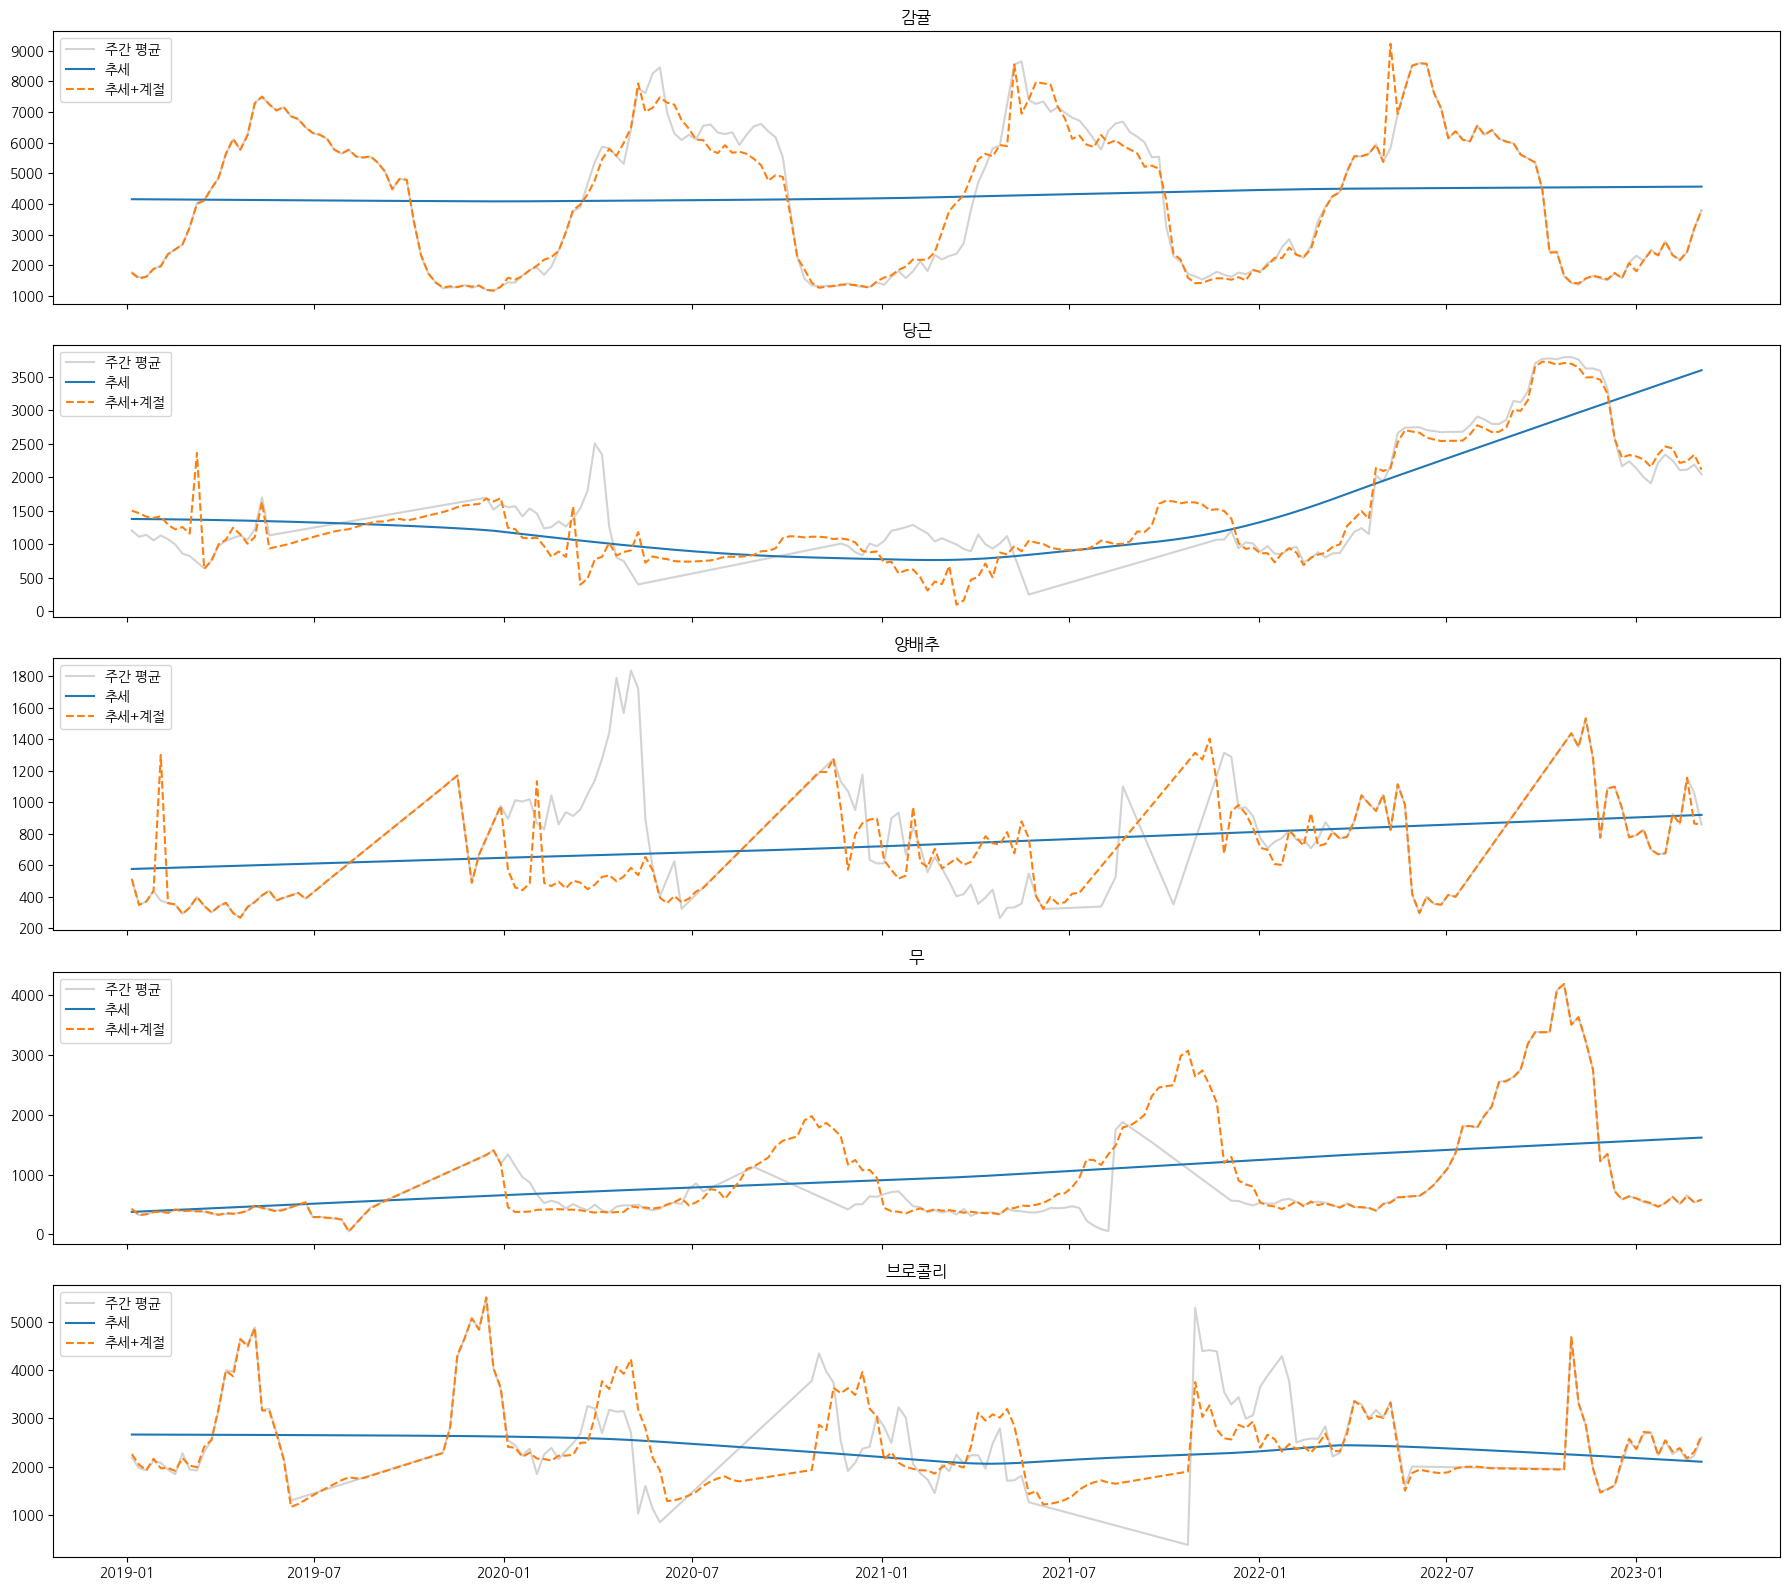

,추세 강도,계절성 강도
감귤,0.090,0.960
당근,0.790,0.430
양배추,0.010,0.220
무,0.330,0.580
브로콜리,0.120,0.550


In [ ]:
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(5, 1, figsize=(18, 16), sharex=True)
strength = {}
for ax, it in zip(axes, ITEMS):
    w = Pclean.loc[:'2023-03-03', item_of[item_of == it].index].mean(axis=1).resample('W').mean().interpolate().bfill()
    r = STL(w, period=52, robust=True).fit()
    strength[ITEM_KR[it]] = {'추세 강도': max(0, 1 - r.resid.var() / (r.trend + r.resid).var()),
                             '계절성 강도': max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())}
    ax.plot(w, c='lightgray', label='주간 평균'); ax.plot(r.trend, label='추세'); ax.plot(r.trend + r.seasonal, ls='--', label='추세+계절')
    ax.set_title(ITEM_KR[it]); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
display(pd.DataFrame(strength).T.round(2))

### EDA 5 - 공급 탄력성 (공급이 1% 늘면 가격은 몇 % 변하나)

In [ ]:
lp, ls_ = np.log(Pnz), np.log(S.where(S > 0))
rows = []
for it in ITEMS:
    cols = item_of[item_of == it].index
    for lag in [0, 7, 28]:
        x = (ls_[cols].shift(lag) - ls_[cols].mean()).stack()
        y = (lp[cols] - lp[cols].mean()).stack()
        xy = pd.concat([x, y], axis=1).dropna()
        rows.append([ITEM_KR[it], lag, np.polyfit(xy[0], xy[1], 1)[0], xy.corr().iloc[0, 1]])
elas = pd.DataFrame(rows, columns=['품목', '공급 lag(일)', '탄력성', '상관'])
display(elas.pivot(index='품목', columns='공급 lag(일)', values='탄력성').round(3))
print('→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.')

공급 lag(일),0,7,28
품목,,,
감귤,-0.333,-0.320,-0.258
당근,-0.174,-0.176,-0.182
무,-0.196,-0.193,-0.189
브로콜리,-0.085,-0.079,-0.028
양배추,-0.136,-0.121,-0.122


→ 같은 날 공급 탄력성은 음수이지만, 28일 전 공급량의 설명력은 크게 줄어든다. 공급량은 보조 피처로만 사용.


### EDA 6 - 예측 지평에 따른 불확실성

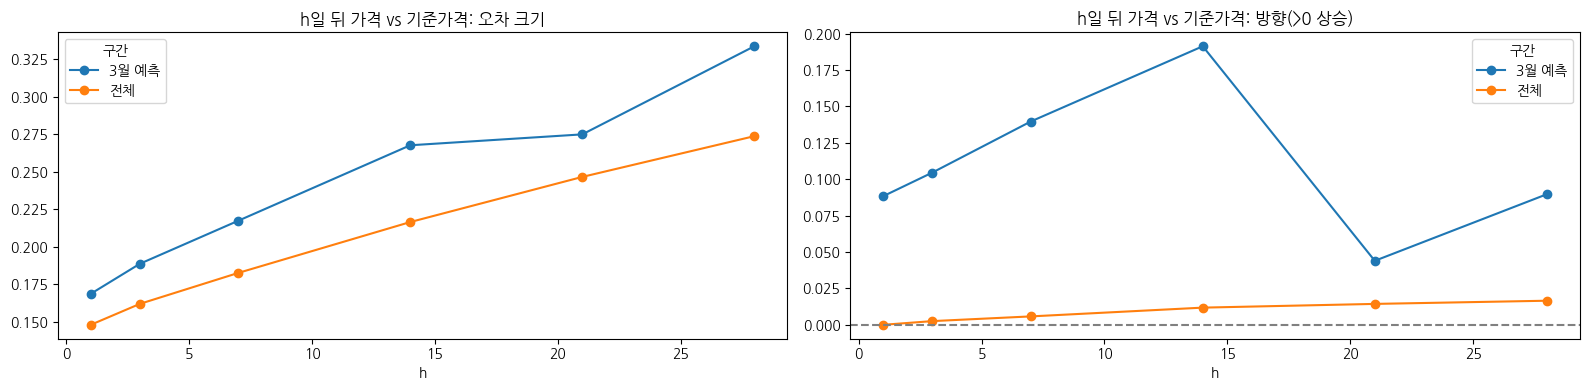

→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습


In [ ]:
level = Pclean.rolling(28, min_periods=3).median()
level = level.fillna(Pclean.rolling(91, min_periods=3).median()).fillna(Pclean.rolling(364, min_periods=1).median())
level = level.fillna(Pclean.expanding().median())                         # 1년 넘게 거래 없음 → 전체 과거 중앙값
level = level.fillna(level.T.groupby(item_of).transform('median').T)        # 거래 이력 자체가 없음 → 같은 품목 중앙값
level = level.fillna(level.T.groupby(item_of).transform('median').T.bfill())
rows = []
for h in [1, 3, 7, 14, 21, 28]:
    lr = np.log(Pnz.shift(-h) / level).loc[:'2023-02-01']
    for m in [None, 3]:
        v = lr if m is None else lr[lr.index.month == (m - 1 if h > 14 else m)]
        v = v.stack()
        rows.append([h, '전체' if m is None else '3월 예측', v.abs().median(), v.median()])
hz = pd.DataFrame(rows, columns=['h', '구간', '|log ratio| 중앙값', 'log ratio 중앙값'])
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
hz.pivot(index='h', columns='구간', values='|log ratio| 중앙값').plot(marker='o', ax=ax[0], title='h일 뒤 가격 vs 기준가격: 오차 크기')
hz.pivot(index='h', columns='구간', values='log ratio 중앙값').plot(marker='o', ax=ax[1], title='h일 뒤 가격 vs 기준가격: 방향(>0 상승)')
ax[1].axhline(0, c='gray', ls='--'); plt.tight_layout(); plt.show()
print('→ h가 커질수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 기준가격보다 오르는 경향이 있다 → 변화율(Ratio)을 따로 학습')

### EDA 7 — 전년 대비 변화율 관점

In [ ]:
trade.columns = ['ym', 'trade_item', 'exp_w', 'exp_amt', 'imp_w', 'imp_amt', 'balance']
TRADE_MAP = {'감귤': 'TG', '당근': 'CR', '양배추': 'CB', '꽃양배추와 브로콜리(broccoli)': 'BC'}
tt = trade[trade.trade_item.isin(TRADE_MAP)].assign(item=lambda d: d.trade_item.map(TRADE_MAP))
tt['ym'] = pd.to_datetime(tt.ym)
tw = tt.pivot(index='ym', columns='item', values='imp_w').add(tt.pivot(index='ym', columns='item', values='exp_w'), fill_value=0)
pm = pd.DataFrame({it: Pnz[item_of[item_of == it].index].mean(axis=1).resample('MS').mean() for it in ITEMS})
yoy = pd.DataFrame({ITEM_KR[it]: [np.log(pm[it]).diff(12).corr(np.log1p(tw[it]).diff(12).shift(k)) for k in [0, 1, 2]]
                    for it in tw.columns}, index=['동월', '1개월 선행', '2개월 선행']).T
display(yoy.round(2))
print('→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)')

,동월,1개월 선행,2개월 선행
브로콜리,0.210,-0.150,-0.250
양배추,0.700,0.540,0.400
당근,0.320,0.180,0.390
감귤,-0.280,-0.020,0.030


→ 상관이 품목마다 부호와 크기가 일정하지 않음 → 모델 피처에서 제외 (과적합 방지)


# 4. 전처리

In [ ]:
nz_mean7 = Pclean.rolling(7, min_periods=1).mean()
nz_mean28 = Pclean.rolling(28, min_periods=1).mean()
nz_std28 = Pclean.rolling(28, min_periods=3).std()
last_price = Pclean.ffill()
trade_rate28 = T.rolling(28, min_periods=1).mean()
trade_rate7 = T.rolling(7, min_periods=1).mean()
# 마지막 거래 후 경과일
idx = np.arange(len(dates))[:, None].repeat(len(SERIES), 1)
last_tr = pd.DataFrame(np.where(T.values == 1, idx, np.nan), index=dates, columns=SERIES).ffill()
days_since = idx - last_tr.values
sup_mean28 = S.where(S > 0).rolling(28, min_periods=1).mean()
# 작년 같은 날 기준 ±3일 거래가격 / 거래확률 (centered)
c_price7 = Pclean.rolling(7, center=True, min_periods=1).mean()
c_trade7 = T.rolling(7, center=True, min_periods=1).mean()
# 품목 공통: 품목 시계열들의 (최근7일 / 기준가격) 평균
mom = (nz_mean7 / level)
item_mom = mom.T.groupby(item_of).transform('mean').T

state = {k: v.values for k, v in dict(level=level, nz_mean7=nz_mean7, nz_mean28=nz_mean28, nz_std28=nz_std28,
                                     last_price=last_price, trade_rate28=trade_rate28, trade_rate7=trade_rate7,
                                     sup_mean28=sup_mean28, c_price7=c_price7, c_trade7=c_trade7,
                                     item_mom=item_mom).items()}
state['days_since'] = days_since
Tv, Pv = T.values, P.values
print({k: v.shape for k, v in state.items()})

{'level': (1551, 39), 'nz_mean7': (1551, 39), 'nz_mean28': (1551, 39), 'nz_std28': (1551, 39), 'last_price': (1551, 39), 'trade_rate28': (1551, 39), 'trade_rate7': (1551, 39), 'sup_mean28': (1551, 39), 'c_price7': (1551, 39), 'c_trade7': (1551, 39), 'item_mom': (1551, 39), 'days_since': (1551, 39)}


학습 데이터: (307944, 31) | 예측 시점 수: 282


,origin,target,series,h,item,corp,loc,cluster,s_code,t_dow,t_month,t_doy,o_dow,level_log,mom7,mom28,cv28,last_ratio,trade_rate7,trade_rate28,days_since,item_mom,sup_log,dow_trade4,ly_ratio,ly_trade,ly2_ratio,y,trade,log_ratio,lev
252020,2022-07-13,2022-08-03,TG_A_S,21,4,0,1,1,30,2,8,215,2,8.717,0.943,1.008,0.119,0.890,0.857,0.857,0.000,0.955,8.349,1.000,0.913,0.714,1.060,"6,251.000",1.000,0.023,"6,108.000"
112952,2021-02-20,2021-02-21,CR_D_J,1,2,3,0,0,17,6,2,52,5,7.150,0.855,0.963,0.124,0.495,0.857,0.714,0.000,0.848,10.945,0.000,0.954,0.857,0.875,0.000,0.000,NaN,"1,274.000"
263889,2022-08-26,2022-09-13,RD_D_S,18,3,3,1,3,25,1,9,256,4,6.735,NaN,NaN,NaN,0.892,0.000,0.000,70.000,1.172,NaN,0.000,NaN,0.000,NaN,0.000,0.000,NaN,841.000
100743,2021-01-07,2021-02-04,CB_A_J,28,1,0,0,0,9,3,2,35,3,6.655,1.085,1.085,0.230,1.064,0.571,0.143,0.000,1.127,9.028,0.250,2.015,0.429,NaN,0.000,0.000,NaN,776.500
136487,2021-05-15,2021-05-31,TG_E_S,16,4,4,1,1,38,0,5,151,5,8.835,1.369,1.008,0.442,1.146,0.714,0.750,0.000,1.134,6.562,1.000,0.933,0.857,0.957,"6,032.000",1.000,-0.130,"6,871.000"


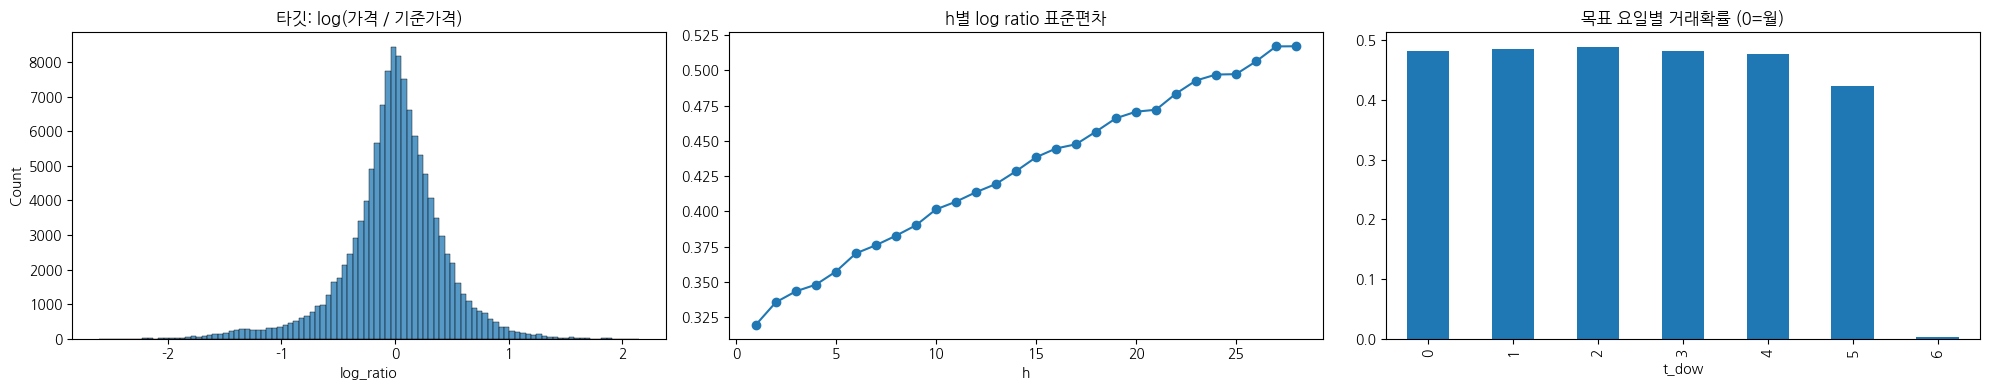

In [ ]:
s_code = np.arange(len(SERIES))
item_code = pd.Series(item_of.values).astype('category').cat.codes.values
clus = cluster.reindex(SERIES).values
corp_code = pd.Series([s[3] for s in SERIES]).astype('category').cat.codes.values
loc_code = (pd.Series([s[5] for s in SERIES]) == 'S').astype(int).values
date_pos = {d: i for i, d in enumerate(dates)}

def make_rows(origin_idx):
    o = np.repeat(origin_idx, len(SERIES) * H)
    s = np.tile(np.repeat(s_code, H), len(origin_idx))
    h = np.tile(np.arange(1, H + 1), len(origin_idx) * len(SERIES))
    t = o + h
    tdate = dates[t]
    lev = state['level'][o, s]
    f = pd.DataFrame({
        'origin': dates[o], 'target': tdate, 'series': np.array(SERIES)[s], 'h': h,
        'item': item_code[s], 'corp': corp_code[s], 'loc': loc_code[s], 'cluster': clus[s], 's_code': s,
        't_dow': tdate.dayofweek, 't_month': tdate.month, 't_doy': tdate.dayofyear, 'o_dow': dates[o].dayofweek,
        'level_log': np.log(lev),
        'mom7': state['nz_mean7'][o, s] / lev, 'mom28': state['nz_mean28'][o, s] / lev,
        'cv28': state['nz_std28'][o, s] / lev, 'last_ratio': state['last_price'][o, s] / lev,
        'trade_rate7': state['trade_rate7'][o, s], 'trade_rate28': state['trade_rate28'][o, s],
        'days_since': state['days_since'][o, s], 'item_mom': state['item_mom'][o, s],
        'sup_log': np.log(state['sup_mean28'][o, s]),
    })
    # 목표 요일과 같은 요일의, 예측 시점 이전 최근 4주 거래 여부 평균
    m0 = np.ceil(h / 7).astype(int)
    f['dow_trade4'] = np.nanmean(np.stack([Tv[t - 7 * (m0 + k), s] for k in range(4)]), axis=0)
    # 작년: 목표일(t-364) 주변 가격 / 작년 예측시점 기준가격 → 작년의 같은 h 변화율
    ly_lev = state['level'][o - 364, s]
    f['ly_ratio'] = state['c_price7'][t - 364, s] / ly_lev
    f['ly_trade'] = state['c_trade7'][t - 364, s]
    f['ly2_ratio'] = np.where(o - 728 >= 0, state['c_price7'][np.maximum(t - 728, 0), s] / state['level'][np.maximum(o - 728, 0), s], np.nan)
    # 타깃
    y = Pv[t, s]
    f['y'] = y
    f['trade'] = (y > 0).astype(float)
    f['log_ratio'] = np.where(y > 0, np.log(np.where(y > 0, y, 1) / lev), np.nan)
    f['lev'] = lev
    return f

FEATS = ['h', 'item', 'corp', 'loc', 'cluster', 's_code', 't_dow', 't_month', 't_doy', 'o_dow', 'level_log',
         'mom7', 'mom28', 'cv28', 'last_ratio', 'trade_rate7', 'trade_rate28', 'days_since', 'item_mom', 'sup_log',
         'dow_trade4', 'ly_ratio', 'ly_trade', 'ly2_ratio']

first_origin = date_pos[pd.Timestamp('2020-01-05')]           # 작년 피처 확보 이후
last_known = date_pos[pd.Timestamp('2023-03-03')]
all_origins = np.arange(first_origin, last_known - H + 1, 4)
DS = make_rows(all_origins)
print('학습 데이터:', DS.shape, '| 예측 시점 수:', len(all_origins))
display(DS.sample(5, random_state=0))
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
sns.histplot(DS.log_ratio.dropna(), bins=100, ax=ax[0]); ax[0].set_title('타깃: log(가격 / 기준가격)')
DS.groupby('h').log_ratio.std().plot(ax=ax[1], marker='o', title='h별 log ratio 표준편차')
DS.groupby('t_dow').trade.mean().plot.bar(ax=ax[2], title='목표 요일별 거래확률 (0=월)')
plt.tight_layout(); plt.show()

In [ ]:
test_rows = make_rows(np.array([last_known]))
test_rows['ID'] = test_rows.series + '_' + test_rows.target.dt.strftime('%Y%m%d')
test_rows = test_rows.set_index('ID').loc[sub.ID].reset_index()
assert len(test_rows) == len(sub) and test_rows.lev.notna().all()

DS.to_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/train_levelratio.csv', index=False)
test_rows.to_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/test_levelratio.csv', index=False)
pd.Series(FEATS).to_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/features_levelratio.csv', index=False, header=False)
print('train:', DS.shape, '| test:', test_rows.shape, '| 피처 수:', len(FEATS))
display(test_rows[['ID', 'origin', 'target', 'h', 'lev', 'dow_trade4', 'ly_ratio']].head())

train: (307944, 31) | test: (1092, 32) | 피처 수: 24


,ID,origin,target,h,lev,dow_trade4,ly_ratio
0,TG_A_J_20230304,2023-03-03,2023-03-04,1,"2,377.000",1.000,1.266
1,TG_A_J_20230305,2023-03-03,2023-03-05,2,"2,377.000",0.000,1.271
2,TG_A_J_20230306,2023-03-03,2023-03-06,3,"2,377.000",1.000,1.244
3,TG_A_J_20230307,2023-03-03,2023-03-07,4,"2,377.000",1.000,1.244
4,TG_A_J_20230308,2023-03-03,2023-03-08,5,"2,377.000",1.000,1.174


## 요약 (EDA + 전처리)

**핵심 아이디어**: 가격을 그대로 예측하지 않고 세 부분으로 나눠서 예측한다.
> **가격 = 거래 여부 × 기준가격 × 변화율**
> - 기준가격: 예측 시점 직전 28일 거래가격의 중앙값
> - 변화율: 기준가격 대비 h일 뒤 가격이 몇 배인지

**EDA에서 알게 된 것**
1. 전체의 약 60%가 가격 0 = 거래가 없는 날 (일요일은 100% 0). 시계열마다 출하 시즌과 쉬는 요일이 다르다.
2. 출하 시즌 패턴으로 묶으면 39개 시계열이 4개 유형으로 나뉜다. 3월에 거의 거래가 없는 시계열 그룹도 따로 있다.
3. 감귤은 계절성이 매우 강하고(0.96), 당근은 추세가 강하다(0.79).
4. 공급이 늘면 가격이 내려간다. 감귤이 가장 민감하다(공급 +1% → 가격 약 -0.33%).
5. 예측 거리(h)가 멀수록 기준가격만으로는 오차가 커지고, 3월에는 가격이 오르는 경향이 있다.
6. 수출입 데이터는 품목마다 상관의 방향이 들쭉날쭉해서 피처에서 뺐다.

**전처리**
- 튀는 가격은 Hampel 필터로 보정 (피처 계산에만 쓰고, 정답 값은 그대로)
- 학습 데이터를 **(예측 시점 × 시계열 × 1~28일 뒤)** 단위로 새로 만듦 → 30만 7944행, 피처 24개
- 주요 피처: 기준가격, 최근 추세, 요일별 최근 거래확률, 작년 같은 시기 변화율, 출하 군집
- 모든 피처는 예측 시점까지의 데이터만 사용 (미래 정보 누수 없음)

# 5. 베이스라인 모델

> **한 줄 요약**: 가격을 바로 예측하지 않고, **거래 확률 × 기준가격 × 변화율**로 나눠서 예측한다.



**예측식**: 예측 가격 = 거래 확률 × 기준가격 × 변화율
- 거래 확률: 목표일 거래 발생 확률 (0~1) → LightGBM 분류
- 기준가격: 예측 시점 직전 28일 거래가격 중앙값 → 전처리 단계에서 계산
- 변화율: 목표일 가격 / 기준가격 → LightGBM 회귀 2개(A, B) 평균

**모델 구성**
- 분류: 거래 여부, 2~4월 목표일 가중치 ×2
- 회귀 A: log 변화율, huber 손실, 2~4월 가중치 ×2
- 회귀 B: 변화율, MSE 손실, 가중치 = 기준가격² (원/kg 단위 MSE와 동일)

**설계 근거**
- 가격 0(거래 없음) 비율 약 60% → 거래 여부와 가격 수준을 분리
- 시계열 간 가격 규모 차이 → 기준가격으로 정규화
- 평가 지표 RMSE → 거래 확률을 0/1로 자르지 않고 기대값으로 결합

**검증**: 예측 시점 4곳(21-03, 22-03, 23-01, 23-02) × 1~28일 뒤 예측, 예측 시점 이전 데이터로만 학습

**입력 파일** (전처리 노트북 `jeju_levelratio.py` 실행 결과): `train_levelratio.csv`, `test_levelratio.csv`, `features_levelratio.csv`

**출력 파일**: `submission_baseline.csv'



### 데이터 불러오기 + 환경 설정

In [ ]:
import logging, os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb

warnings.filterwarnings('ignore')
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
try:
    import koreanize_matplotlib
except ImportError:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.float_format', '{:,.1f}'.format)

TRAIN_PATH = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/train_levelratio.csv'
TEST_PATH  = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/test_levelratio.csv'
FEAT_PATH  = r'/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/features_levelratio.csv'

ITEM_KR = {'TG': '감귤', 'CR': '당근', 'CB': '양배추', 'RD': '무', 'BC': '브로콜리'}

In [ ]:
#1. 데이터 불러오기

missing = [p for p in (TRAIN_PATH, TEST_PATH, FEAT_PATH) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f'{missing} 가 없습니다 → 전처리 코드(jeju_levelratio.py)를 먼저 끝까지 실행하세요.')

DS = pd.read_csv(TRAIN_PATH, parse_dates=['origin', 'target'])
TEST = pd.read_csv(TEST_PATH, parse_dates=['origin', 'target'])
FEATS = pd.read_csv(FEAT_PATH, header=None)[0].tolist()   # 피처 이름 24개
DS['품목'] = DS.series.str[:2].map(ITEM_KR)

print('train:', DS.shape, '| test:', TEST.shape, '| 피처 수:', len(FEATS))
print('예측 시점 범위:', DS.origin.min().date(), '~', DS.origin.max().date())
print('거래 비율: {:.1%}'.format(DS.trade.mean()))

train: (307944, 32) | test: (1092, 32) | 피처 수: 24
예측 시점 범위: 2020-01-05 ~ 2023-02-02
거래 비율: 40.6%


###검증 설계 — 예측 시점 4곳

In [ ]:
# test와 똑같이 예측 시점 1곳에서 1~28일 뒤를 예측
# - 3월 근처 2곳(2021, 2022): test와 계절이 같음 → 가장 중요한 지표
# - 최근 2곳(2023-01, 2023-02): 가장 최근 가격 흐름
# 각 검증에서는 목표일이 예측 시점 이전인 행만 학습에 사용

origins = np.sort(DS.origin.unique())
def nearest_origin(day):
    return pd.Timestamp(origins[origins <= np.datetime64(day)][-1])

VALID = {'21-03': nearest_origin('2021-03-03'), '22-03': nearest_origin('2022-03-03'),
         '23-01': nearest_origin('2023-01-06'), '23-02': pd.Timestamp(origins[-1])}
MARCH = ['21-03', '22-03']
for k, o in VALID.items():
    print(k, '예측 시점:', o.date(), '→ 목표:', (o + pd.Timedelta(days=1)).date(), '~', (o + pd.Timedelta(days=28)).date())

def split(o):
    return DS[DS.target <= o], DS[DS.origin == o]

rmse = lambda y, p: float(np.sqrt(np.mean((np.asarray(y, float) - np.asarray(p, float)) ** 2)))

21-03 예측 시점: 2021-02-28 → 목표: 2021-03-01 ~ 2021-03-28
22-03 예측 시점: 2022-03-03 → 목표: 2022-03-04 ~ 2022-03-31
23-01 예측 시점: 2023-01-05 → 목표: 2023-01-06 ~ 2023-02-02
23-02 예측 시점: 2023-02-02 → 목표: 2023-02-03 ~ 2023-03-02


### 손실 함수 설계

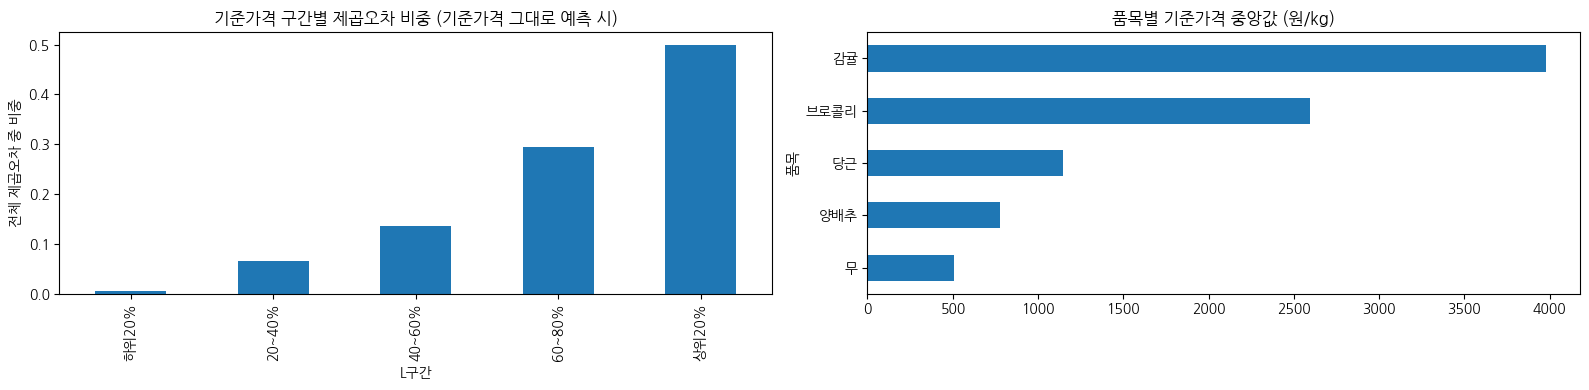

상위 20% 가격 구간이 전체 제곱오차의 50%를 차지 → 가격이 큰 행을 정확히 맞히는 것이 점수에 직결


In [ ]:
# 가격 규모(L)별로 오차가 얼마나 점수에 기여하는지 확인

d = DS[DS.trade == 1]
d = d.assign(L구간=pd.qcut(d.lev, 5, labels=['하위20%', '20~40%', '40~60%', '60~80%', '상위20%']))
naive_err = (d.y - d.lev) ** 2           # 변화율 1(기준가격 그대로)로 예측했을 때의 제곱오차
share = naive_err.groupby(d.L구간).sum() / naive_err.sum()
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
share.plot.bar(ax=ax[0], title='기준가격 구간별 제곱오차 비중 (기준가격 그대로 예측 시)')
ax[0].set_ylabel('전체 제곱오차 중 비중')
d.groupby('품목').lev.median().sort_values().plot.barh(ax=ax[1], title='품목별 기준가격 중앙값 (원/kg)')
plt.tight_layout(); plt.show()
print('상위 20% 가격 구간이 전체 제곱오차의 {:.0%}를 차지 → 가격이 큰 행을 정확히 맞히는 것이 점수에 직결'.format(share.iloc[-1]))

### 모델 정의

In [ ]:
PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
HUBER = dict(PARAMS, objective='huber', alpha=0.3)
L2 = dict(PARAMS, objective='regression')

def season_w(d, k=2.0):
    """목표일이 2~4월이면 가중치 k (예측 구간 3월과 비슷한 시즌을 더 중요하게)"""
    return np.where(d.t_month.isin([2, 3, 4]), k, 1.0)

def fit_all(tr):
    pos = tr[tr.trade == 1]
    m = {}
    m['clf_v1'] = lgb.LGBMClassifier(**PARAMS).fit(tr[FEATS], tr.trade)
    m['reg_v1'] = lgb.LGBMRegressor(**HUBER).fit(pos[FEATS], pos.log_ratio)
    m['clf'] = lgb.LGBMClassifier(**PARAMS).fit(tr[FEATS], tr.trade, sample_weight=season_w(tr))
    m['reg_A'] = lgb.LGBMRegressor(**HUBER).fit(pos[FEATS], pos.log_ratio, sample_weight=season_w(pos))
    m['reg_B'] = lgb.LGBMRegressor(**L2).fit(pos[FEATS], np.exp(pos.log_ratio), sample_weight=pos.lev.values ** 2)
    return m

def predict_all(m, d):
    X, L = d[FEATS], d.lev.values
    p_v1 = m['clf_v1'].predict_proba(X)[:, 1]
    p = m['clf'].predict_proba(X)[:, 1]
    price_A = L * np.exp(m['reg_A'].predict(X))
    price_B = L * np.clip(m['reg_B'].predict(X), 0, None)
    return pd.DataFrame({
        'prob': p, 'price_A': price_A, 'price_B': price_B,
        'v1': p_v1 * L * np.exp(m['reg_v1'].predict(X)),
        'A': p * price_A, 'B': p * price_B, 'v2': p * (price_A + price_B) / 2,
    }, index=d.index)


### 모델 검증

21-03 완료 | 학습 행: 111,384
22-03 완료 | 학습 행: 211,848
23-01 완료 | 학습 행: 295,932
23-02 완료 | 학습 행: 303,576


,21-03,22-03,23-01,23-02,3월 평균,전체 평균
규칙: 기준가격 × 요일거래,864.2,"1,236.7",816.2,845.5,"1,050.4",940.7
v1 (기존),680.4,990.1,860.1,749.4,835.2,820.0
A log + 시즌가중,666.8,990.9,835.3,739.8,828.9,808.2
B 가격단위 손실,638.1,985.9,868.7,782.9,812.0,818.9
v2 = A·B 평균 (최종),634.0,984.8,850.3,757.9,809.4,806.8


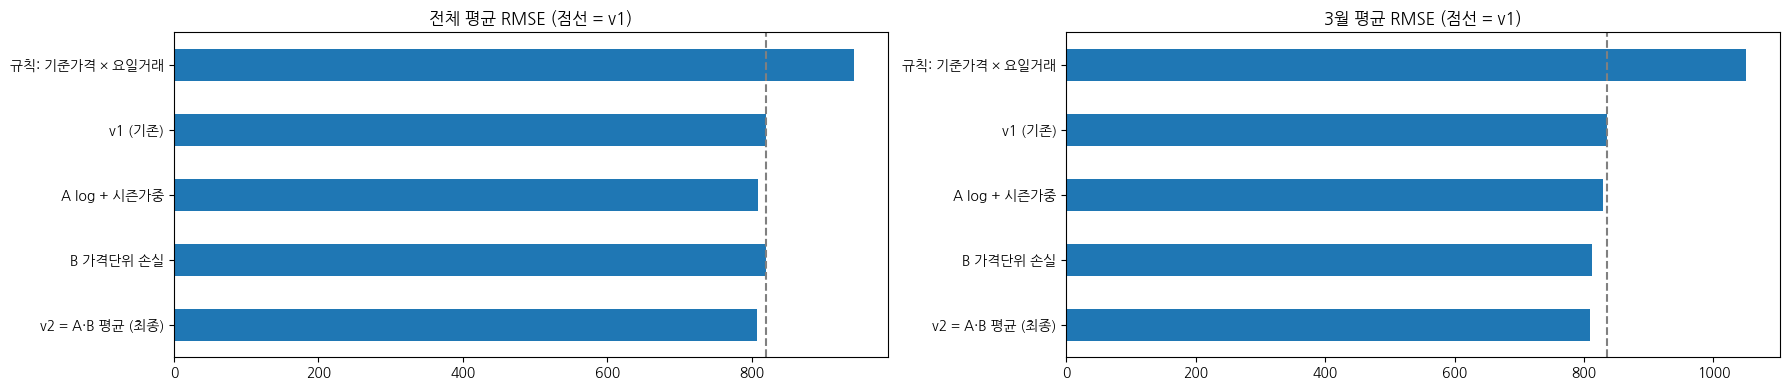

In [ ]:
def rule(d):   # 규칙 베이스라인: 기준가격 × (같은 요일 최근 4주에 절반 이상 거래)
    return d.lev * (d.dow_trade4 > 0.5)

preds, models = {}, {}
for k, o in VALID.items():
    tr, va = split(o)
    models[k] = fit_all(tr)
    preds[k] = pd.concat([va, predict_all(models[k], va).assign(rule=rule(va))], axis=1)
    print(k, '완료 | 학습 행:', f'{len(tr):,}')

COLS = {'rule': '규칙: 기준가격 × 요일거래', 'v1': 'v1 (기존)', 'A': 'A log + 시즌가중',
        'B': 'B 가격단위 손실', 'v2': 'v2 = A·B 평균 (최종)'}
res = pd.DataFrame({k: {COLS[c]: rmse(v.y, v[c]) for c in COLS} for k, v in preds.items()})
res['3월 평균'] = res[MARCH].mean(axis=1)
res['전체 평균'] = res[list(VALID)].mean(axis=1)
display(res)

fig, ax = plt.subplots(1, 2, figsize=(18, 4))
for a, col in zip(ax, ['전체 평균', '3월 평균']):
    res[col].plot.barh(ax=a, title=f'{col} RMSE (점선 = v1)'); a.invert_yaxis()
    a.axvline(res.loc[COLS['v1'], col], c='gray', ls='--')
plt.tight_layout(); plt.show()


## 결과 분석

### 품목별 오차 기여도 (무엇이 좋아졌는지)

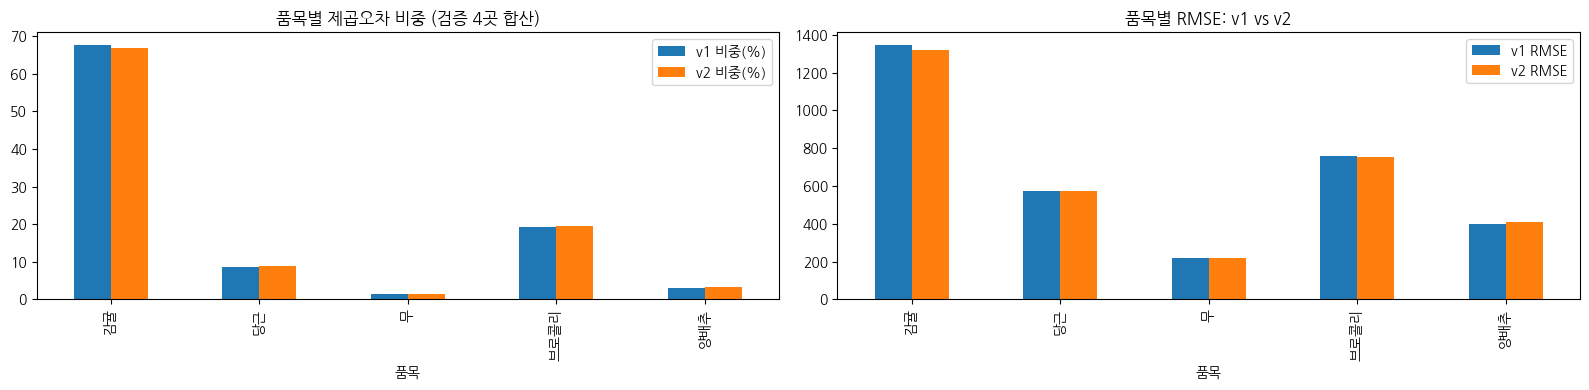

,v1 비중(%),v2 비중(%),v1 RMSE,v2 RMSE,개선폭
품목,,,,,
감귤,67.6,66.9,"1,345.3","1,319.6",25.7
당근,8.6,8.8,573.0,572.1,0.8
무,1.5,1.5,220.6,220.7,-0.1
브로콜리,19.4,19.6,759.2,752.4,6.8
양배추,2.9,3.2,396.5,409.0,-12.5


In [ ]:
# RMSE² = 행별 제곱오차의 평균이므로, (품목별 제곱오차 합 / 전체 제곱오차 합)으로 점수에 대한 기여도를 나눌 수 있다.

allv = pd.concat([v.assign(fold=k) for k, v in preds.items()])
sq = pd.DataFrame({m: ((allv.y - allv[m]) ** 2).groupby(allv.품목).sum() for m in ['v1', 'v2']})
item_tbl = (sq / sq.sum() * 100).rename(columns=lambda c: c + ' 비중(%)').join(
    allv.groupby('품목').apply(lambda d: pd.Series({'v1 RMSE': rmse(d.y, d.v1), 'v2 RMSE': rmse(d.y, d.v2)})))
item_tbl['개선폭'] = item_tbl['v1 RMSE'] - item_tbl['v2 RMSE']
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
item_tbl[['v1 비중(%)', 'v2 비중(%)']].plot.bar(ax=ax[0], title='품목별 제곱오차 비중 (검증 4곳 합산)')
item_tbl[['v1 RMSE', 'v2 RMSE']].plot.bar(ax=ax[1], title='품목별 RMSE: v1 vs v2')
plt.tight_layout(); plt.show()
display(item_tbl.round(1))

### 품목별 편향 (체계적으로 높게/낮게 예측하는가)

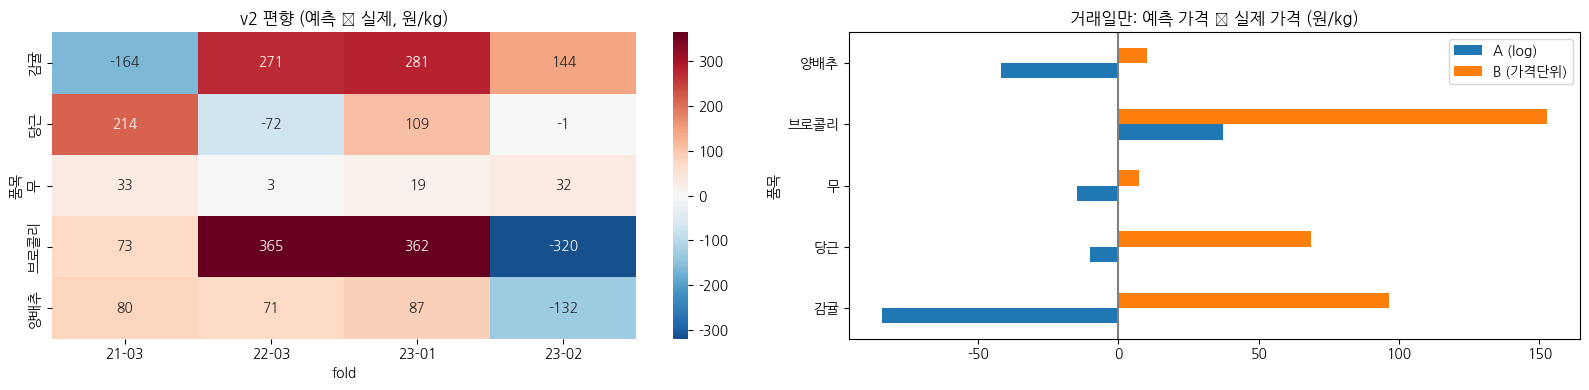

,A (log),B (가격단위)
품목,,
감귤,-84.1,96.6
당근,-9.9,68.5
무,-14.7,7.5
브로콜리,37.3,152.7
양배추,-41.7,10.4


→ 두 회귀기의 편향 방향이 다르면 평균(v2)에서 서로 상쇄된다


In [ ]:
# 편향 = 평균(예측 − 실제). 0보다 크면 과대 예측, 작으면 과소 예측.
# 오른쪽은 '거래가 있었던 날만' 가격 부분(확률을 곱하기 전)의 편향을 본 것.

bias = allv.groupby(['품목', 'fold']).apply(lambda d: (d.v2 - d.y).mean()).unstack()
tr_days = allv[allv.trade == 1]
bias_price = pd.DataFrame({'A (log)': (tr_days.price_A - tr_days.y).groupby(tr_days.품목).mean(),
                           'B (가격단위)': (tr_days.price_B - tr_days.y).groupby(tr_days.품목).mean()})
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
sns.heatmap(bias, annot=True, fmt='.0f', cmap='RdBu_r', center=0, ax=ax[0]); ax[0].set_title('v2 편향 (예측 − 실제, 원/kg)')
bias_price.plot.barh(ax=ax[1], title='거래일만: 예측 가격 − 실제 가격 (원/kg)'); ax[1].axvline(0, c='gray')
plt.tight_layout(); plt.show()
display(bias_price.round(1))
print('→ 두 회귀기의 편향 방향이 다르면 평균(v2)에서 서로 상쇄된다')

### 보정(calibration) (확인 거래 확률은 믿을 만한지)

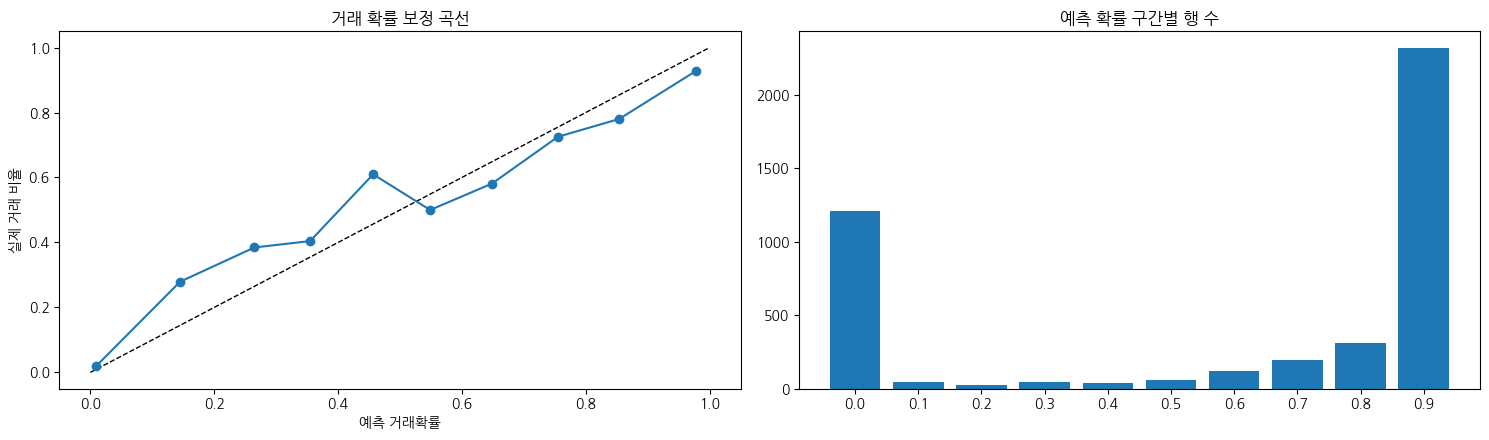

AUC: 0.940 | Brier score: 0.082 (0에 가까울수록 좋음)
확률이 0.1~0.9 사이인 애매한 행 비율: 19.3% → 이 행들에서 기대값 결합이 효과를 냄


In [ ]:
# 확률 × 가격 --> "확률 0.7"이라고 말한 날에 실제로 70% 거래가 일어나야 함.
# 예측 확률을 10구간으로 나눠, 구간별 실제 거래 비율과 비교한다(대각선에 가까울수록 좋음).

from sklearn.metrics import brier_score_loss, roc_auc_score
allv['p_bin'] = pd.cut(allv.prob, np.linspace(0, 1, 11), include_lowest=True)
cal = allv.groupby('p_bin', observed=False).agg(예측확률=('prob', 'mean'), 실제거래비율=('trade', 'mean'), 행수=('trade', 'size'))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].plot(cal.예측확률, cal.실제거래비율, 'o-')
ax[0].set_xlabel('예측 거래확률'); ax[0].set_ylabel('실제 거래 비율'); ax[0].set_title('거래 확률 보정 곡선')
ax[1].bar(range(len(cal)), cal.행수); ax[1].set_xticks(range(len(cal))); ax[1].set_xticklabels([f'{i/10:.1f}' for i in range(len(cal))])
ax[1].set_title('예측 확률 구간별 행 수')
plt.tight_layout(); plt.show()
print('AUC: {:.3f} | Brier score: {:.3f} (0에 가까울수록 좋음)'.format(roc_auc_score(allv.trade, allv.prob), brier_score_loss(allv.trade, allv.prob)))
print('확률이 0.1~0.9 사이인 애매한 행 비율: {:.1%} → 이 행들에서 기대값 결합이 효과를 냄'.format(allv.prob.between(.1, .9).mean()))

### 예측 거리(h) · 요일별 오차

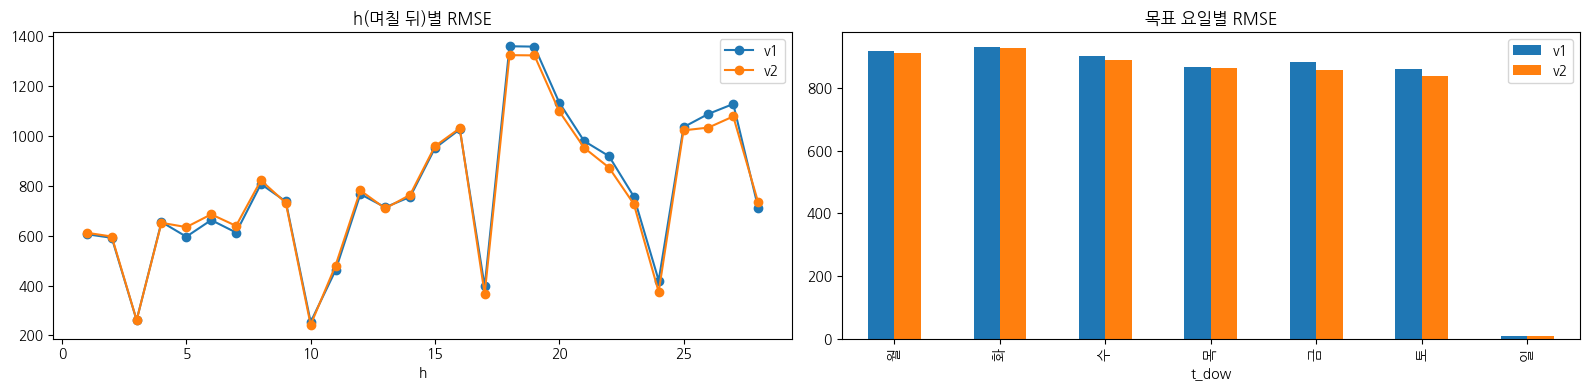

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
allv.groupby('h').apply(lambda d: pd.Series({'v1': rmse(d.y, d.v1), 'v2': rmse(d.y, d.v2)})).plot(ax=ax[0], marker='o', title='h(며칠 뒤)별 RMSE')
allv.groupby('t_dow').apply(lambda d: pd.Series({'v1': rmse(d.y, d.v1), 'v2': rmse(d.y, d.v2)})).rename(
    index=dict(enumerate('월화수목금토일'))).plot.bar(ax=ax[1], title='목표 요일별 RMSE')
plt.tight_layout(); plt.show()

### 피처 중요도 — 세 모델은 각각 무엇을 보는지

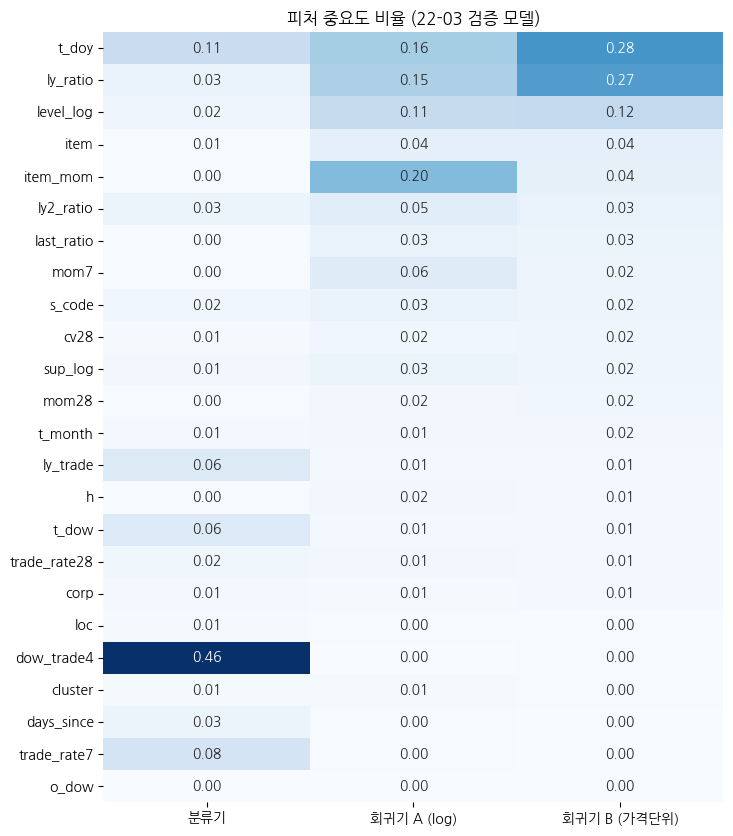

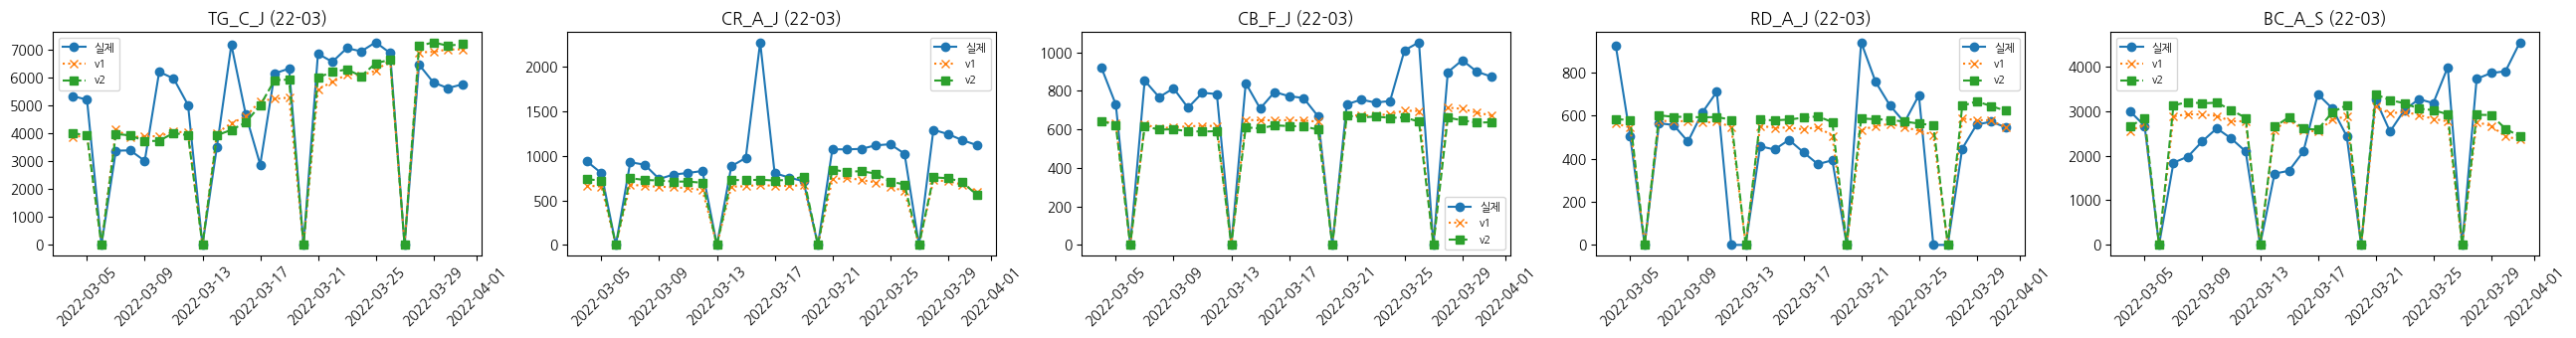

In [ ]:
m = models['22-03']
imp = pd.DataFrame({'분류기': m['clf'].booster_.feature_importance('gain'),
                    '회귀기 A (log)': m['reg_A'].booster_.feature_importance('gain'),
                    '회귀기 B (가격단위)': m['reg_B'].booster_.feature_importance('gain')}, index=FEATS)
imp = imp / imp.sum()
plt.figure(figsize=(8, 10))
sns.heatmap(imp.sort_values('회귀기 B (가격단위)', ascending=False), annot=True, fmt='.2f', cmap='Blues', cbar=False)
plt.title('피처 중요도 비율 (22-03 검증 모델)'); plt.show()

va = preds['22-03']
fig, axes = plt.subplots(1, 5, figsize=(26, 3.5))
for ax, it in zip(axes, ITEM_KR):
    s = va[va.series.str[:2] == it].groupby('series').y.sum().idxmax(); d = va[va.series == s]
    ax.plot(d.target, d.y, 'o-', label='실제'); ax.plot(d.target, d.v1, 'x:', label='v1'); ax.plot(d.target, d.v2, 's--', label='v2')
    ax.set_title(f'{s} (22-03)'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

### 최종 학습 & 제출

In [ ]:
final = fit_all(DS)
tp = predict_all(final, TEST)
submission = pd.DataFrame({'ID': TEST.ID, 'answer': tp.v2.values})
assert submission.answer.notna().all() and len(submission) == 1092
submission.to_csv('/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/submission_baseline.csv', index=False)

chk = TEST.assign(품목=TEST.series.str[:2].map(ITEM_KR), v1=tp.v1.values, v2=tp.v2.values).groupby('품목')[['v1', 'v2']].mean()
display(chk.rename(columns={'v1': 'v1 예측 평균', 'v2': 'v2 예측 평균'}))
print(submission.answer.describe())
display(submission.head(10))

,v1 예측 평균,v2 예측 평균
품목,,
감귤,"3,523.2","3,600.6"
당근,982.9,"1,045.0"
무,328.9,349.4
브로콜리,"1,737.2","1,719.7"
양배추,442.6,467.3


count   1,092.0
mean    1,639.2
std     1,747.7
min         0.0
25%        84.2
50%       677.4
75%     2,581.8
max     6,676.2
Name: answer, dtype: float64


,ID,answer
0,TG_A_J_20230304,"3,514.8"
1,TG_A_J_20230305,1.2
2,TG_A_J_20230306,"3,698.0"
3,TG_A_J_20230307,"3,640.9"
4,TG_A_J_20230308,"3,677.5"
5,TG_A_J_20230309,"3,699.3"
6,TG_A_J_20230310,"3,735.3"
7,TG_A_J_20230311,"3,656.1"
8,TG_A_J_20230312,1.0
9,TG_A_J_20230313,"3,657.3"


## 요약 (베이스라인)


**방법**: 예측 가격 = 거래 확률 × 기준가격 × 변화율
- 거래 확률: LightGBM 분류 모델
- 변화율: LightGBM 회귀 모델 2개의 평균
- A: log 변화율 학습 (안정적, 최근 구간에 강함)
- B: 변화율 그대로 + 기준가격² 가중치 → **대회 지표(원/kg RMSE)를 직접 줄이도록 학습** (3월 구간에 강함)
- 목표일이 2~4월인 행은 가중치 2 (예측 구간이 3월)

**검증 방법**: test와 같이 예측 시점 1곳에서 1~28일 뒤를 예측. 예측 시점 4곳, 그 시점 이전 데이터로만 학습(누수 없음)

**검증 결과 (RMSE)**
- 21-03: 634.0 / 22-03: 984.8 / 23-01: 850.3 / 23-02: 757.9
- **3월 평균 809.4 / 전체 평균 806.8**

**분석으로 알게 된 것**
1. 가격 상위 20% 행이 전체 제곱오차의 50%를 차지한다 → 비싼 품목을 잘 맞히는 게 핵심
2. 점수의 약 67%가 감귤 오차에서 나온다
3. 회귀 모델 A는 가격을 낮게, B는 높게 예측하는 경향 → 평균하면 서로 상쇄된다
4. 거래 확률이 잘 맞는다 (AUC 0.940, Brier 0.082), 애매한 확률(0.1~0.9)인 행은 19%

# 6. 모델 성능 향상, 후처리



### 추가 피처 생성

In [ ]:
# 추가 피처 생성

EXTRA_FEATS = [
    'mom_gap_7_28',
    'mom_ratio_7_28',
    'last_gap_7',
    'trade_gap_7_28',
    'ly_deviation',
    'ly2_gap',
    't_doy_sin',
    't_doy_cos',
    'is_weekend',
    'is_march',
    'h_ratio'
]

def add_extra_features(df):

    d = df.copy()

    # 1) 최근 7일과 28일 가격 흐름 차이
    d['mom_gap_7_28'] = d['mom7'] - d['mom28']

    # 단기 추세 / 중기 추세
    d['mom_ratio_7_28'] = (
        d['mom7'] / d['mom28'].replace(0, np.nan)
    )

    # 2) 최근 거래가격과 최근 7일 평균의 차이
    d['last_gap_7'] = d['last_ratio'] - d['mom7']

    # 3) 최근 거래 빈도의 변화
    d['trade_gap_7_28'] = (
        d['trade_rate7'] - d['trade_rate28']
    )

    # 4) 전년 동기 대비 가격 변화
    d['ly_deviation'] = d['ly_ratio'] - 1

    # 5) 2년 전과 1년 전 가격 변화율 차이
    d['ly2_gap'] = d['ly2_ratio'] - d['ly_ratio']

    # 6) 연중 날짜의 순환 특성
    d['t_doy_sin'] = np.sin(
        2 * np.pi * (d['t_doy'] - 1) / 365.25
    )

    d['t_doy_cos'] = np.cos(
        2 * np.pi * (d['t_doy'] - 1) / 365.25
    )

    # 7) 요일 및 3월 여부
    d['is_weekend'] = d['t_dow'].isin([5, 6]).astype(int)
    d['is_march'] = (d['t_month'] == 3).astype(int)

    # 8) 예측 지평 정규화
    d['h_ratio'] = d['h'] / 28.0

    # 무한대 값 처리
    d[EXTRA_FEATS] = d[EXTRA_FEATS].replace(
        [np.inf, -np.inf], np.nan
    )

    return d


# 기존 피처와 중복되지 않도록 정리
FEATS_BASE = [c for c in FEATS if c not in EXTRA_FEATS]

DS = add_extra_features(DS)
TEST = add_extra_features(TEST)

FEATS = FEATS_BASE + EXTRA_FEATS

print('기존 피처 수:', len(FEATS_BASE))
print('추가 피처 수:', len(EXTRA_FEATS))
print('최종 피처 수:', len(FEATS))

assert set(FEATS).issubset(DS.columns)
assert set(FEATS).issubset(TEST.columns)

display(DS[FEATS].head())

기존 피처 수: 24
추가 피처 수: 11
최종 피처 수: 35


,h,item,corp,loc,cluster,s_code,t_dow,t_month,t_doy,o_dow,level_log,mom7,mom28,cv28,last_ratio,trade_rate7,trade_rate28,days_since,item_mom,sup_log,dow_trade4,ly_ratio,ly_trade,ly2_ratio,mom_gap_7_28,mom_ratio_7_28,last_gap_7,trade_gap_7_28,ly_deviation,ly2_gap,t_doy_sin,t_doy_cos,is_weekend,is_march,h_ratio
0,1,0,0,0,0,0,0,1,6,6,8.3,0.6,1.0,0.3,0.6,0.6,0.8,1.0,0.7,8.5,1.0,0.8,0.9,NaN,-0.4,0.6,-0.0,-0.2,-0.2,NaN,0.1,1.0,0,0,0.0
1,2,0,0,0,0,0,1,1,7,6,8.3,0.6,1.0,0.3,0.6,0.6,0.8,1.0,0.7,8.5,1.0,0.8,0.9,NaN,-0.4,0.6,-0.0,-0.2,-0.2,NaN,0.1,1.0,0,0,0.1
2,3,0,0,0,0,0,2,1,8,6,8.3,0.6,1.0,0.3,0.6,0.6,0.8,1.0,0.7,8.5,0.8,0.8,0.9,NaN,-0.4,0.6,-0.0,-0.2,-0.2,NaN,0.1,1.0,0,0,0.1
3,4,0,0,0,0,0,3,1,9,6,8.3,0.6,1.0,0.3,0.6,0.6,0.8,1.0,0.7,8.5,0.8,0.8,0.9,NaN,-0.4,0.6,-0.0,-0.2,-0.2,NaN,0.1,1.0,0,0,0.1
4,5,0,0,0,0,0,4,1,10,6,8.3,0.6,1.0,0.3,0.6,0.6,0.8,1.0,0.7,8.5,1.0,0.8,0.9,NaN,-0.4,0.6,-0.0,-0.2,-0.2,NaN,0.2,1.0,0,0,0.2


### Optuna를 이용한 하이퍼파라미터 최적화

In [ ]:
# 1. Optuna 설치
!pip install -q optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)


# 2. 개선 모델 정의
def fit_models_improved(tr, params, seed=0):

    pos = tr[tr['trade'] == 1]

    common = dict(params)
    common.update({
        'subsample_freq': 1,
        'verbose': -1,
        'n_jobs': -1
    })

    models_improved = {}

    # 거래 여부 분류 모델
    models_improved['clf'] = lgb.LGBMClassifier(
        **common,
        objective='binary',
        random_state=seed
    ).fit(
        tr[FEATS],
        tr['trade'],
        sample_weight=season_w(tr)
    )

    # A: log 변화율 회귀 모델
    models_improved['reg_A'] = lgb.LGBMRegressor(
        **common,
        objective='huber',
        alpha=0.3,
        random_state=seed + 1
    ).fit(
        pos[FEATS],
        pos['log_ratio'],
        sample_weight=season_w(pos)
    )

    # B: 가격 변화율 회귀 모델
    models_improved['reg_B'] = lgb.LGBMRegressor(
        **common,
        objective='regression',
        random_state=seed + 2
    ).fit(
        pos[FEATS],
        np.exp(pos['log_ratio']),
        sample_weight=pos['lev'].values ** 2
    )

    return models_improved


def predict_models_improved(models, d):

    X = d[FEATS]
    L = d['lev'].values

    # 거래 확률
    prob = models['clf'].predict_proba(X)[:, 1]
    prob = np.clip(prob, 0, 1)

    # A: log 변화율 예측
    log_ratio_A = models['reg_A'].predict(X)
    price_A = L * np.exp(log_ratio_A)

    # B: 변화율 예측
    ratio_B = models['reg_B'].predict(X)
    price_B = L * np.clip(ratio_B, 0, None)

    return pd.DataFrame({
        'prob': prob,
        'price_A': price_A,
        'price_B': price_B
    }, index=d.index)

In [ ]:
# 3. 하이퍼파라미터 탐색
def objective(trial):

    max_depth = trial.suggest_int(
        'max_depth', 4, 8
    )

    params = {
        'n_estimators': trial.suggest_int(
            'n_estimators', 300, 700, step=100
        ),

        'learning_rate': trial.suggest_float(
            'learning_rate', 0.02, 0.08, log=True
        ),

        'max_depth': max_depth,

        'num_leaves': trial.suggest_int(
            'num_leaves', 15, min(63, 2 ** max_depth)
        ),

        'min_child_samples': trial.suggest_int(
            'min_child_samples', 20, 100, step=10
        ),

        'subsample': trial.suggest_float(
            'subsample', 0.7, 0.95
        ),

        'colsample_bytree': trial.suggest_float(
            'colsample_bytree', 0.7, 0.95
        ),

        'reg_alpha': trial.suggest_float(
            'reg_alpha', 0.0, 2.0
        ),

        'reg_lambda': trial.suggest_float(
            'reg_lambda', 0.0, 8.0
        )
    }

    fold_scores = {}

    for k, o in VALID.items():

        tr, va = split(o)

        model = fit_models_improved(
            tr, params, seed=0
        )

        pred = predict_models_improved(
            model, va
        )

        # 우선 A와 B를 50:50으로 결합
        predicted_price = (
            pred['prob'].values *
            (
                0.5 * pred['price_A'].values
                + 0.5 * pred['price_B'].values
            )
        )

        fold_scores[k] = rmse(
            va['y'].values,
            predicted_price
        )

    # 3월 검증 점수를 더 중요하게 반영
    march_score = np.mean([
        fold_scores['21-03'],
        fold_scores['22-03']
    ])

    recent_score = np.mean([
        fold_scores['23-01'],
        fold_scores['23-02']
    ])

    # 3월 80%, 최근 구간 20%
    final_score = 0.8 * march_score + 0.2 * recent_score

    return final_score


study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=15,
    n_jobs=1,
    show_progress_bar=True
)

best_params = study.best_params.copy()

print('최적 검증 점수:', round(study.best_value, 4))
print('\n최적 하이퍼파라미터')

display(
    pd.DataFrame(
        best_params.items(),
        columns=['하이퍼파라미터', '최적값']
    )
)

  0%|          | 0/15 [00:00<?, ?it/s]

최적 검증 점수: 804.6881

최적 하이퍼파라미터


,하이퍼파라미터,최적값
0,max_depth,4.0
1,n_estimators,300.0
2,learning_rate,0.0
3,num_leaves,15.0
4,min_child_samples,20.0
5,subsample,0.8
6,colsample_bytree,0.9
7,reg_alpha,1.7
8,reg_lambda,5.5


In [ ]:
# 4. 여러 시드 모델 앙상블
SEEDS = [0, 21, 42]

preds_improved = {}

for k, o in VALID.items():

    tr, va = split(o)

    seed_predictions = []

    for seed in SEEDS:

        model = fit_models_improved(
            tr,
            best_params,
            seed=seed
        )

        pred = predict_models_improved(
            model,
            va
        )

        seed_predictions.append(pred)

    # 세 모델의 예측값 평균
    pred_mean = seed_predictions[0].copy()

    for col in pred_mean.columns:

        pred_mean[col] = np.mean(
            [p[col].values for p in seed_predictions],
            axis=0
        )

    result = va[
        ['y', 'trade', '품목', 'series', 'h', 'target']
    ].copy()

    preds_improved[k] = result.join(pred_mean)

    print(
        k,
        '| 검증 행 수:',
        len(va),
        '| 완료'
    )

21-03 | 검증 행 수: 1092 | 완료
22-03 | 검증 행 수: 1092 | 완료
23-01 | 검증 행 수: 1092 | 완료
23-02 | 검증 행 수: 1092 | 완료


In [ ]:
# 5. A/B 앙상블 가중치 최적화

alpha_results = []

ALPHAS = np.round(
    np.linspace(0, 1, 21), 2
)

for alpha in ALPHAS:

    fold_scores = {}

    for k, d in preds_improved.items():

        pred_price = (
            d['prob'].values *
            (
                alpha * d['price_A'].values
                + (1 - alpha) * d['price_B'].values
            )
        )

        fold_scores[k] = rmse(
            d['y'].values,
            pred_price
        )

    march_score = np.mean([
        fold_scores['21-03'],
        fold_scores['22-03']
    ])

    recent_score = np.mean([
        fold_scores['23-01'],
        fold_scores['23-02']
    ])

    selection_score = (
        0.8 * march_score
        + 0.2 * recent_score
    )

    alpha_results.append({
        'A 비중': alpha,
        'B 비중': 1 - alpha,
        '3월 평균 RMSE': march_score,
        '최근 구간 평균 RMSE': recent_score,
        '선택 점수': selection_score
    })


alpha_table = pd.DataFrame(alpha_results)

alpha_table = alpha_table.sort_values(
    '선택 점수'
).reset_index(drop=True)

best_alpha = float(
    alpha_table.loc[0, 'A 비중']
)

print('최적 A 비중:', best_alpha)
print('최적 B 비중:', 1 - best_alpha)

display(alpha_table.head(10))

최적 A 비중: 0.7
최적 B 비중: 0.30000000000000004


,A 비중,B 비중,3월 평균 RMSE,최근 구간 평균 RMSE,선택 점수
0,0.7,0.3,809.8,783.6,804.5
1,0.8,0.2,810.1,782.5,804.6
2,0.7,0.3,809.5,784.8,804.6
3,0.8,0.2,810.5,781.3,804.7
4,0.6,0.4,809.3,786.1,804.7
5,0.8,0.2,811.0,780.3,804.8
6,0.6,0.4,809.2,787.4,804.9
7,0.9,0.1,811.5,779.2,805.1
8,0.5,0.5,809.2,788.8,805.1
9,0.9,0.1,812.2,778.2,805.4


In [ ]:
# 6. 개선 모델 검증 예측값 계산
for k, d in preds_improved.items():

    d['pred_raw'] = (
        d['prob'] *
        (
            best_alpha * d['price_A']
            + (1 - best_alpha) * d['price_B']
        )
    )

    # 예측 가격은 음수가 될 수 없도록 처리
    d['pred_raw'] = d['pred_raw'].clip(lower=0)


# 베이스라인과 개선 모델 비교
baseline_scores = {
    k: rmse(preds[k]['y'], preds[k]['v2'])
    for k in VALID
}

improved_scores = {
    k: rmse(preds_improved[k]['y'], preds_improved[k]['pred_raw'])
    for k in VALID
}

comparison = pd.DataFrame({
    '베이스라인 RMSE': baseline_scores,
    '개선 모델 RMSE': improved_scores
})

comparison.loc['3월 평균'] = [
    np.mean([
        baseline_scores['21-03'],
        baseline_scores['22-03']
    ]),
    np.mean([
        improved_scores['21-03'],
        improved_scores['22-03']
    ])
]

comparison.loc['전체 평균'] = [
    np.mean(list(baseline_scores.values())),
    np.mean(list(improved_scores.values()))
]

display(comparison.round(2))

,베이스라인 RMSE,개선 모델 RMSE
21-03,634.0,655.2
22-03,984.8,964.3
23-01,850.3,804.8
23-02,757.9,762.5
3월 평균,809.4,809.8
전체 평균,806.8,796.7


### 후처리: 품목별 예측 편향 보정

In [ ]:
# 7. 품목별 보정 계수 계산 함수
def estimate_item_scale(history, prior_n=250):

    g = history.groupby('품목').agg(
        n=('y', 'size'),
        sum_actual=('y', 'sum'),
        sum_pred=('pred_raw', 'sum')
    )

    # 실제 가격 합계 / 예측 가격 합계
    raw_scale = (
        g['sum_actual']
        / g['sum_pred'].clip(lower=1e-9)
    )

    # 표본 수에 따라 보정값을 1에 가깝게 축소
    scale = (
        1
        + (raw_scale - 1)
        * g['n'] / (g['n'] + prior_n)
    )

    # 지나치게 큰 보정 방지
    scale = scale.clip(0.85, 1.15)

    return scale.fillna(1.0)


# 8. 순차 검증으로 후처리 효과 확인
fold_order = list(VALID.keys())

history = []

calibration_results = []

for k in fold_order:

    d = preds_improved[k]

    if len(history) > 0:

        previous = pd.concat(history)

        scales = estimate_item_scale(previous)

        factor = (
            d['품목']
            .map(scales)
            .fillna(1.0)
        )

    else:

        # 첫 번째 검증 구간은 이전 자료가 없으므로 보정하지 않음
        factor = 1.0

    calibrated_pred = d['pred_raw'] * factor

    raw_score = rmse(
        d['y'],
        d['pred_raw']
    )

    calibrated_score = rmse(
        d['y'],
        calibrated_pred
    )

    calibration_results.append({
        '검증 구간': k,
        '보정 전 RMSE': raw_score,
        '보정 후 RMSE': calibrated_score
    })

    # 현재 검증 결과는 다음 검증 구간의 보정에 사용
    history.append(
        d[['y', '품목', 'pred_raw']].copy()
    )


calibration_table = pd.DataFrame(calibration_results)

display(calibration_table.round(2))

raw_mean = calibration_table['보정 전 RMSE'].mean()
cal_mean = calibration_table['보정 후 RMSE'].mean()

print('보정 전 평균 RMSE:', round(raw_mean, 2))
print('보정 후 평균 RMSE:', round(cal_mean, 2))

# 순차 검증에서 개선된 경우에만 최종 보정 적용
USE_ITEM_CALIBRATION = cal_mean < raw_mean

print(
    '최종 품목별 보정 적용 여부:',
    USE_ITEM_CALIBRATION
)


if USE_ITEM_CALIBRATION:

    all_oof = pd.concat([
        d[['y', '품목', 'pred_raw']]
        for d in preds_improved.values()
    ])

    final_item_scale = estimate_item_scale(all_oof)

    print('\n최종 품목별 보정 계수')
    display(final_item_scale.to_frame('보정 계수').round(4))

else:

    final_item_scale = pd.Series(dtype=float)

    print('검증 결과 보정 효과가 확인되지 않아 보정을 적용하지 않습니다.')

,검증 구간,보정 전 RMSE,보정 후 RMSE
0,21-03,655.2,655.2
1,22-03,964.3,957.0
2,23-01,804.8,777.9
3,23-02,762.5,798.8


보정 전 평균 RMSE: 796.7
보정 후 평균 RMSE: 797.26
최종 품목별 보정 적용 여부: False
검증 결과 보정 효과가 확인되지 않아 보정을 적용하지 않습니다.


In [ ]:
# 9. 전체 데이터 최종 학습
final_seed_predictions = []

for seed in SEEDS:

    model = fit_models_improved(
        DS,
        best_params,
        seed=seed
    )

    pred = predict_models_improved(
        model,
        TEST
    )

    final_seed_predictions.append(pred)

    print('최종 모델 학습 완료:', seed)


# 세 모델 예측값 평균
final_pred = final_seed_predictions[0].copy()

for col in final_pred.columns:

    final_pred[col] = np.mean(
        [p[col].values for p in final_seed_predictions],
        axis=0
    )


# A/B 최적 비중 결합
final_answer = (
    final_pred['prob'].values *
    (
        best_alpha * final_pred['price_A'].values
        + (1 - best_alpha) * final_pred['price_B'].values
    )
)

# 품목별 후처리 적용
if USE_ITEM_CALIBRATION:

    test_items = TEST['series'].str[:2].map(ITEM_KR)

    scale = (
        test_items
        .map(final_item_scale)
        .fillna(1.0)
        .values
    )

    final_answer = final_answer * scale


# 음수 예측 방지
final_answer = np.clip(final_answer, 0, None)


# 제출 파일 생성
submission_improved = pd.DataFrame({
    'ID': TEST['ID'].values,
    'answer': final_answer
})


# 최종 확인
assert len(submission_improved) == len(TEST)
assert submission_improved['answer'].notna().all()
assert (submission_improved['answer'] >= 0).all()
assert submission_improved['ID'].equals(TEST['ID'])


SAVE_PATH = (
    '/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/'
    'submission_improved.csv'
)

submission_improved.to_csv(
    SAVE_PATH,
    index=False
)

print('최종 제출 파일 저장 완료')
print(SAVE_PATH)

print('\n최종 예측값 요약')
display(submission_improved['answer'].describe())

print('\n품목별 예측 평균')
final_check = TEST.copy()
final_check['품목'] = final_check['series'].str[:2].map(ITEM_KR)
final_check['예측가격'] = final_answer

display(
    final_check.groupby('품목')['예측가격']
    .agg(['mean', 'median', 'min', 'max'])
    .round(2)
)

print('\n제출 파일 상위 10개')
display(submission_improved.head(10))

최종 모델 학습 완료: 0
최종 모델 학습 완료: 21
최종 모델 학습 완료: 42
최종 제출 파일 저장 완료
/content/drive/MyDrive/ESAA_OB/OB_data/Project(3)/submission_improved.csv

최종 예측값 요약


,answer
count,"1,092.0"
mean,"1,624.5"
std,"1,679.4"
min,1.1
25%,94.7
50%,690.9
75%,"2,583.8"
max,"5,597.1"



품목별 예측 평균


,mean,median,min,max
품목,,,,
감귤,"3,524.0","4,297.5",6.1,"5,597.1"
당근,"1,036.7","1,236.8",1.2,"2,361.2"
무,337.8,464.1,1.1,561.9
브로콜리,"1,734.6","2,408.9",5.1,"2,904.5"
양배추,508.7,616.1,1.8,"1,394.1"



제출 파일 상위 10개


,ID,answer
0,TG_A_J_20230304,"3,728.1"
1,TG_A_J_20230305,10.0
2,TG_A_J_20230306,"3,780.6"
3,TG_A_J_20230307,"3,780.6"
4,TG_A_J_20230308,"3,772.9"
5,TG_A_J_20230309,"3,769.3"
6,TG_A_J_20230310,"3,766.6"
7,TG_A_J_20230311,"3,717.1"
8,TG_A_J_20230312,9.7
9,TG_A_J_20230313,"3,782.0"


In [ ]:
# 10. 최종 성능 비교
final_comparison = pd.DataFrame({
    '베이스라인': baseline_scores,
    '개선 모델': improved_scores
})

final_comparison['개선량'] = (
    final_comparison['베이스라인']
    - final_comparison['개선 모델']
)

final_comparison['개선율(%)'] = (
    final_comparison['개선량']
    / final_comparison['베이스라인']
    * 100
)

final_comparison.loc['3월 평균'] = [
    np.mean([
        baseline_scores['21-03'],
        baseline_scores['22-03']
    ]),
    np.mean([
        improved_scores['21-03'],
        improved_scores['22-03']
    ]),
    0,
    0
]

final_comparison.loc['전체 평균'] = [
    np.mean(list(baseline_scores.values())),
    np.mean(list(improved_scores.values())),
    0,
    0
]

# 평균 행의 개선량과 개선율 재계산
for idx in ['3월 평균', '전체 평균']:

    final_comparison.loc[idx, '개선량'] = (
        final_comparison.loc[idx, '베이스라인']
        - final_comparison.loc[idx, '개선 모델']
    )

    final_comparison.loc[idx, '개선율(%)'] = (
        final_comparison.loc[idx, '개선량']
        / final_comparison.loc[idx, '베이스라인']
        * 100
    )

display(final_comparison.round(2))

,베이스라인,개선 모델,개선량,개선율(%)
21-03,634.0,655.2,-21.2,-3.4
22-03,984.8,964.3,20.6,2.1
23-01,850.3,804.8,45.5,5.3
23-02,757.9,762.5,-4.6,-0.6
3월 평균,809.4,809.8,-0.3,-0.0
전체 평균,806.8,796.7,10.1,1.2
